# The Extended Kalman Filter (EKF) 

Course: Recursive State Estimation for Dynamic Systems (SoSe 2026)

Institute: Geodätisches Institut Hannover

Team Members :

1.Arjun Mohandas( Matriculation Nummer:10081891)

2.Aswin Sam(Matriculation Nummer:10082498)

3.Edvin Tony Thampy(Matriculation Nummer:10082986)

This notebook implements the Extended Kalman Filter (EKF) for estimating the 3D position and velocity of a robot from noisy total-station observations.The unconstrained and constrained versions are implemented and compared.

The implementation follows the notation used in the lecture and exercise sessions.

## Use Of AI

ChatGPT was used for coding review, debugging assistance and researching information.It was mainly used to summarise topics and informations and document them into latex code including equations which were too lengthy and time consuming too write.It was used to understand and minimize code implementations and document information, handle data, plot graphs and diagrams with ease. It was mainly used to check for errors in code and evaluate diagrams to understand their behaviour.The implementations differed from filter to filter.Eventhough AI was used all implementation decisions and final results were verified by us.

## AIM

The objective of the Extended Kalman Filter (EKF) is to estimate the 3D position and velocity states of the robot directly from the nonlinear total station observations.

$$
\mathbf{l}^{(k)} =
\begin{bmatrix}
H^{(k)} \\
V^{(k)} \\
D^{(k)}
\end{bmatrix}
$$

where

$$
H^{(k)} = \text{Horizontal Angle}, \quad
V^{(k)} = \text{Vertical Angle}, \quad \text{and} \quad
D^{(k)} = \text{Slope Distance}.
$$

Unlike the Linear Time Discrete Kalman Filter (LKDF), which uses Cartesian observations,the EKF operates directly on the nonlinear observation model. The nonlinear measurement equations are linearized at each epoch using the Jacobian matrix of the measurement function.

Here we have to consider two versions of the EKF:

1.The Unconstrained EKF

2.The Constrained EKF


## PRE-PROCESSING
### Imports and Loading given datafiles


In [63]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# Read observation and ground truth data
obsrv = pd.read_csv("Data/polar0011_slower_0.csv")
gtrue = pd.read_csv("Data/tracker0011_slower_0.csv")


In [64]:
#Conversion of observations from polar coordinates to cartesian coordinates:
obsrv["H_radian"] = np.deg2rad(obsrv["H [deg]"]) #degree to radian conversion
obsrv["V_radian"]= np.deg2rad(obsrv["V [deg]"])
obsrv["D_m"]= obsrv["D [mm]"] / 1000  #mm to m conversion


X_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.cos(obsrv["H_radian"] )

Y_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.sin(obsrv["H_radian"] )

Z_obsrv = obsrv["D_m"]*np.cos(obsrv["V_radian"])

obsrv["X_obsrv_cart"] = X_obsrv
obsrv["Y_obsrv_cart"] = Y_obsrv
obsrv["Z_obsrv_cart"] = Z_obsrv

X_gtrue = gtrue["X [m]"].values #converting pandas to numpy
Y_gtrue = gtrue["Y [m]"].values
Z_gtrue = gtrue["Z [m]"].values


In [65]:
#finding step length dt....

obsrv["time"] = pd.to_datetime(obsrv["Time [HH:MM:SS]"],format="%H:%M:%S.%f") # convert to timestamp 
time_inseconds=(obsrv["time"]-obsrv["time"].iloc[0]) # subtract the column from first timestap to get time in seconds
time_inseconds = time_inseconds.dt.total_seconds()# .dt.total_seconds to get seconds
time_inseconds= time_inseconds.values# convert to np arrays
dt= np.mean(np.diff(time_inseconds)) #Take mean of differences and round it.
dt=round(dt,3)

# The Unconstrained Extended Kalman Filter

The unconstrained EKF does not impose any geometric, physical or kinematic constraints on the estimated states. Instead, the state estimation process relies on the dynamic model, process noise model, nonlinear observation model and measurement update equations.

# PROCEDURE
## State Vector

$$
\mathbf{x}^{(k)} =
\begin{bmatrix}
X^{(k)} \\
Y^{(k)} \\
Z^{(k)} \\
V_X^{(k)} \\
V_Y^{(k)} \\
V_Z^{(k)}
\end{bmatrix}
$$

### The dynamic system model is

$$
\mathbf{x}^{(k)}
=
\mathbf{\Phi}
\mathbf{x}^{(k-1)}
+
\mathbf{w}^{(k-1)}
$$

where $$
\mathbf{w}^{(k-1)}
\sim
\mathcal{N}
\left(
\mathbf{0},
\mathbf{Q}_{ww}
\right)
$$

In [66]:
#System matrices...

X0 = obsrv["X_obsrv_cart"].iloc[0]
Y0 = obsrv["Y_obsrv_cart"].iloc[0]
Z0 = obsrv["Z_obsrv_cart"].iloc[0]

#time interval or time step

dt=0.01 # calculated for LKDF

#State vector
X_k = np.array([X0,Y0,Z0,0,0,0])

#Transition matrix

Phi_k = np.array([
    [1,0,0,dt,0,0],
    [0,1,0,0,dt,0],
    [0,0,1,0,0,dt],
    [0,0,0,1,0,0],
    [0,0,0,0,1,0],
    [0,0,0,0,0,1]])

#Process Noise Covariance Matrix Q_WW

sigma_a=2.5

#Then derive Q_ww usimg sigma_a:
Q_ww = sigma_a**2 * np.array([
    [dt**4/4,0,0,dt**3/2,0,0],
    [0,dt**4/4,0,0,dt**3/2,0],
    [0,0,dt**4/4,0,0,dt**3/2],
    [dt**3/2,0,0,dt**2,0,0],
    [0,dt**3/2,0,0,dt**2,0],
    [0,0,dt**3/2,0,0,dt**2]])

#Jacobian Function
#we should convert polar to cartesian using jacobian.
def observation_jacobian(H_radian, V_radian, D_m):
    return np.array([[-D_m * np.sin(V_radian) * np.sin(H_radian),
            D_m * np.cos(V_radian) * np.cos(H_radian),
            np.sin(V_radian) * np.cos(H_radian)],
            [D_m * np.sin(V_radian) * np.cos(H_radian),
            D_m * np.cos(V_radian) * np.sin(H_radian),
            np.sin(V_radian) * np.sin(H_radian)],
            [0,-D_m * np.sin(V_radian),np.cos(V_radian)]])

#Initial or State covariance matrix,Q_xx

sigma_H = np.deg2rad(0.0014)#given in task description
sigma_V = np.deg2rad(0.0014)#given in task description
D_0 = obsrv["D_m"].iloc[0] # Distance for zeroth measurement
sigma_D0 = 0.0025 * D_0+ 0.0025 # Equation provided in task description

Q_HVD0 = np.diag([
    sigma_H**2,
    sigma_V**2,
    sigma_D0**2])# Polar covariance matrix

J0 = observation_jacobian(
    obsrv["H_radian"].iloc[0],
    obsrv["V_radian"].iloc[0],
    obsrv["D_m"].iloc[0])

Q_XYZ0 = J0 @ Q_HVD0 @ J0.T

Q_xx = np.diag([
    Q_XYZ0[0,0],   # X variance
    Q_XYZ0[1,1],   # Y variance
    Q_XYZ0[2,2],   # Z variance
    1,             # Vx variance
    1,             # Vy variance
    1])            # Vz variance


## Nonlinear Observation Function

h(x) converts the state from Cartesian coordinates into the measurements that the Total Station would observe.

### Relationship Between the State and Measurement Models in the EKF

In the Linear Kalman Filter (LKF), the Total Station measurements

$$
(H, V, D)
$$

were first converted into Cartesian coordinates

$$
(X, Y, Z)
$$

before being used by the filter. Consequently, the filter operated entirely in the Cartesian coordinate system.

In the Extended Kalman Filter (EKF), the measurements remain in their original form and therefore direct comparison between the measurement vector

$$
\mathbf{l}^{(k)} =
\begin{bmatrix}
H^{(k)} \\
V^{(k)} \\
D^{(k)}
\end{bmatrix}
$$

and the predicted state vector

$$
\hat{\mathbf{x}}^{(k)-} =
\begin{bmatrix}
X^{(k)} \\
Y^{(k)} \\
Z^{(k)} \\
V_X^{(k)} \\
V_Y^{(k)} \\
V_Z^{(k)}
\end{bmatrix}
$$

is not possible because they are expressed in different coordinate systems.

To overcome this issue, the EKF employs a nonlinear observation function

$$
\mathbf{h}(\mathbf{x}),
$$

which transforms the predicted Cartesian state into the measurement space. Specifically, the position components

$$
(X,Y,Z)
$$

are converted into the corresponding Total Station observations

$$
(H,V,D).
$$

The observation function is defined as

$$
D = \sqrt{X^2 + Y^2 + Z^2},
$$

$$
H = \tan^{-1}\!\left(\frac{Y}{X}\right)
= \operatorname{atan2}(Y,X),
$$

$$
V = \tan^{-1}\!\left(
\frac{Z}{\sqrt{X^2 + Y^2}}
\right).
$$

Therefore,

$$
\mathbf{h}(\mathbf{x}) :
(X,Y,Z)
\longrightarrow
(H,V,D).
$$

The predicted measurement vector is obtained as

$$
\hat{\mathbf{l}}^{(k)}
=
\mathbf{h}\!\left(
\hat{\mathbf{x}}^{(k)-}
\right).
$$

This nonlinear observation model is linearized at each epoch using its Jacobian matrix, which is the fundamental principle underlying the Extended Kalman Filter.

In [67]:
## Nonlinear Observation Function

def h(x):
    X = x[0] 
    Y = x[1]
    Z = x[2]

    D = np.sqrt(X**2 + Y**2 + Z**2) #slope

    H = np.arctan2(Y,X)# horizontal angle

    V = np.arccos(Z/D) #zenith angle

    return np.array([H,V,D])
   

### Summary

| Quantity | Formula | Meaning |
|----------|----------|----------|
| $X$ | Cartesian coordinate | Position in X direction |
| $Y$ | Cartesian coordinate | Position in Y direction |
| $Z$ | Cartesian coordinate | Height |
| $\rho$ | $\sqrt{X^2 + Y^2}$ | Horizontal distance |
| $D$ | $\sqrt{X^2 + Y^2 + Z^2}$ | 3D slope distance |
| $H$ | $\operatorname{atan2}(Y,X)$ | Horizontal angle (left-right direction) |
| $V$ | $\operatorname{acos}(Z,D)$ | Vertical angle (Zenith Angle/up-down direction) |

## Jacobian Matrix of the Observation Model

The Total Station measurements consist of the horizontal angle, vertical angle, and slope distance:

$$
\mathbf{l}^{(k)}=
\begin{bmatrix}
H^{(k)}\\
V^{(k)}\\
D^{(k)}
\end{bmatrix}.
$$

where
$$
\rho=\sqrt{X^2+Y^2}
$$

is defined as the horizontal distance and

$$
D=\sqrt{X^2+Y^2+Z^2}
$$

as the three-dimensional slope distance.

The nonlinear observation equations are

$$
H=\operatorname{atan2}(Y,X),
$$

$$
V=\operatorname{atan2}(Z,\rho),
$$

$$
D=\sqrt{X^2+Y^2+Z^2}.
$$

Since the observation model is nonlinear, it must be linearized about the predicted state estimate using the Jacobian matrix

$$
\mathbf{H}_k=
\frac{\partial h(\mathbf{x})}{\partial \mathbf{x}}.
$$

---

### Partial Derivatives of the Horizontal Angle

For

$$
H=\operatorname{atan2}(Y,X),
$$

the partial derivatives are

$$
\frac{\partial H}{\partial X}
=
-\frac{Y}{X^2+Y^2}
=
-\frac{Y}{\rho^2},
$$

$$
\frac{\partial H}{\partial Y}
=
\frac{X}{X^2+Y^2}
=
\frac{X}{\rho^2},
$$

$$
\frac{\partial H}{\partial Z}=0.
$$

---

### Partial Derivatives of the Vertical Angle

For

$$
V=\operatorname{atan2}(Z,\rho),
$$

the partial derivatives are

$$
\frac{\partial V}{\partial X}
=
-\frac{XZ}{\rho D^2},
$$

$$
\frac{\partial V}{\partial Y}
=
-\frac{YZ}{\rho D^2},
$$

$$
\frac{\partial V}{\partial Z}
=
\frac{\rho}{D^2}.
$$

---

### Partial Derivatives of the Slope Distance

For

$$
D=\sqrt{X^2+Y^2+Z^2},
$$

the partial derivatives are

$$
\frac{\partial D}{\partial X}
=
\frac{X}{D},
$$

$$
\frac{\partial D}{\partial Y}
=
\frac{Y}{D},
$$

$$
\frac{\partial D}{\partial Z}
=
\frac{Z}{D}.
$$

---

### Jacobian Matrix

Combining all partial derivatives gives the observation Jacobian matrix:

$$
\mathbf{H}_k=
\begin{bmatrix}
-\dfrac{Y}{\rho^2} &
\dfrac{X}{\rho^2} &
0 &
0 &
0 &
0
\\[10pt]
-\dfrac{XZ}{\rho D^2} &
-\dfrac{YZ}{\rho D^2} &
\dfrac{\rho}{D^2} &
0 &
0 &
0
\\[10pt]
\dfrac{X}{D} &
\dfrac{Y}{D} &
\dfrac{Z}{D} &
0 &
0 &
0
\end{bmatrix}.
$$

The last three columns are zero because the observation model depends only on the position coordinates $(X,Y,Z)$ and does not directly depend on the velocity components $(V_x,V_y,V_z)$.

In [68]:
#Jacobain EKF
def H_jacobian(x):
    
    X, Y, Z = x[0], x[1], x[2]

    rho = np.sqrt(X**2 + Y**2)
    D = np.sqrt(X**2 + Y**2 + Z**2) #slope distance

    H_k= np.array([[-Y/(rho**2),X/(rho**2),0,0,0,0],
                  [X*Z/(D**2 * rho),Y*Z/(D**2 * rho),-rho/(D**2),0,0,0],
                        [X/D,Y/D,Z/D,0,0,0]])

    return H_k


In [69]:
#prediction step begins......
N = len(obsrv)

estimates_ucekf= np.zeros((N,6))
X_plus_history_ucekf= np.zeros((N, 6))
Q_plus_history_ucekf = np.zeros((N, 6, 6))

estimates_ucekf[0] = X_k
X_plus_history_ucekf[0] = X_k
Q_plus_history_ucekf[0] = Q_xx

I6 = np.eye(6)

# Store Kalman Gain
K_history = np.zeros((N, 3))

# Start Timing

start_time = time.perf_counter()
   
for k in range(1, N):

    X_k_minus = Phi_k @ X_k

    Q_xx_minus = (Phi_k@ Q_xx@ Phi_k.T + Q_ww)

#observation vector
    l_k = np.array([obsrv["H_radian"].iloc[k],
                    obsrv["V_radian"].iloc[k],
                    obsrv["D_m"].iloc[k]])

#Observation/measurement covariance
    
    sigma_H = np.deg2rad(0.0014) # given 

    sigma_V = np.deg2rad(0.0014) #given

    sigma_D = (0.0025 *obsrv["D_m"].iloc[k]+ 0.0025) #given

    Q_HVD = np.diag([sigma_H**2,
                             sigma_V**2,
                             sigma_D**2])   
#Q_ll not needed.
    
#initiate the jacobian EKF

    H_k= H_jacobian(X_k_minus)

#Update step begins....
    
#Innovation(Residual)
        
    I = l_k - h(X_k_minus)
##The predicted Cartesian state is converted into predicted polar measurements using h(x). 
##These predicted measurements are compared with the actual total station measurements.
##The difference between them is called the innovation (or residual), which quantifies 
##the disagreement between the prediction and the observation and is used by the EKF to
##update the state estimate.
    
# Horizontal angle wrapping

    I[0] = np.arctan2(np.sin(I[0]),np.cos(I[0]))
    
# Innovation Covariance
    
    S = (H_k@ Q_xx_minus@ H_k.T+Q_HVD)


#h(x) gives predicted measurements, while H_k gives the measurement sensitivities needed for covariance propagation.


# Kalman Gain
   

    K = (Q_xx_minus@ H_k.T@ np.linalg.inv(S))
    
#corrected step(posteriori)

    X_k_plus = (X_k_minus+K @ I)

    
# Covariance Update
    
    Q_xx_plus = (I6- K @ H_k) @ Q_xx_minus

#updating estimates values
    
    X_plus_history_ucekf[k] = X_k_plus
    
    Q_plus_history_ucekf[k] = Q_xx_plus
    
    estimates_ucekf[k] = X_k_plus

    X_k = X_k_plus

    Q_xx = Q_xx_plus

# Stop Timing

    end_time = time.perf_counter()

    computation_time = end_time - start_time

            
# Extracting States...

X_est = estimates_ucekf[:,0]
Y_est = estimates_ucekf[:,1]
Z_est = estimates_ucekf[:,2]

Vx_est = estimates_ucekf[:,3]
Vy_est = estimates_ucekf[:,4]
Vz_est = estimates_ucekf[:,5]

print("="*60)
print("COMPUTATION TIME FOR UNCONSTRAINED EKF")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")


COMPUTATION TIME FOR UNCONSTRAINED EKF
Total Time : 0.637131 s
Average Time per Epoch : 0.00009030 s
Average Time per Epoch : 0.0903 ms


## OBSERVATIONS
### 1. 2D Estimated vs ground truth trajectory

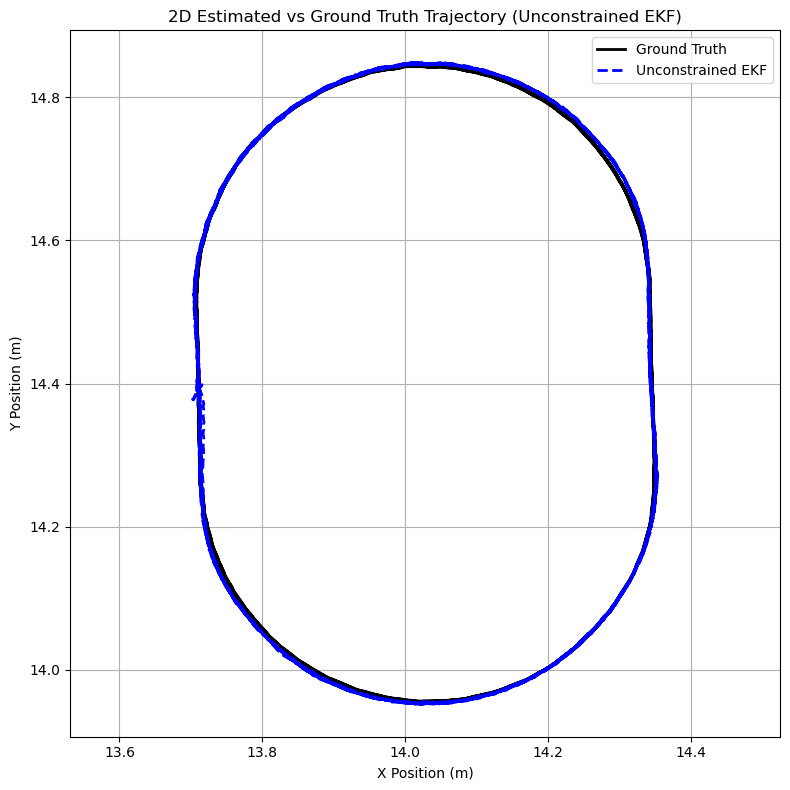

In [70]:

plt.figure(figsize=(8,8))

# Ground Truth
plt.plot(
    X_gtrue,
    Y_gtrue,
    'k',
    linewidth=2,
    label='Ground Truth')

# Unconstrained EKF
plt.plot(
    X_est,
    Y_est,
    'b--',
    linewidth=2,
    label='Unconstrained EKF')

plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')

plt.title('2D Estimated vs Ground Truth Trajectory (Unconstrained EKF)')

plt.axis('equal')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/EKF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

- The estimated trajectory closely follows the ground truth throughout the complete race track, demonstrating accurate recursive state estimation by the unconstrained Extended Kalman Filter.

- The nonlinear measurement model enables the filter to process the total station observations more accurately than the Linear Kalman Filter by directly accounting for the nonlinear relationship between the Cartesian state variables and the measured angles and distance.

- Along the straight sections, the estimated trajectory almost completely overlaps the ground truth because the constant-velocity motion model accurately represents the target dynamics over short sampling intervals.

- During the curved sections, only small trajectory deviations are observed. These occur because the prediction model still assumes constant velocity, whereas the target undergoes turning motion with unmodelled centripetal acceleration.

- Compared with the Linear Kalman Filter, the trajectory deviations are smaller because the Jacobian matrix is updated at every recursive iteration, allowing the measurement sensitivities to adapt continuously to the current target position.

- A small transient offset is observed near the transition between the curved and straight sections. This represents a temporary prediction error that is gradually corrected through successive recursive measurement updates.

- The estimated trajectory remains smooth and continuous throughout the complete experiment, with no oscillations, discontinuities, or divergence, confirming the numerical stability of the implemented Extended Kalman Filter. Overall, the trajectory demonstrates that the Extended Kalman Filter provides an accurate and physically consistent state estimation when processing nonlinear Total Station measurements.

## 2.Reference 3D Velocity Computation

The reference 3D velocity was derived from the ground-truth position trajectory using **numerical differentiation**. Since the dataset does not provide ground-truth velocity measurements, the reference velocities were obtained by numerically differentiating the ground-truth position using the sampling interval dt. The NumPy `gradient()` function was employed, which computes the derivative using the **central difference method** for interior data points and **first-order forward and backward differences** at the trajectory boundaries. For a detailed explanataion with equations refer the linear kalman filter.

In [71]:
vx_true = np.gradient(X_gtrue,dt)
vy_true = np.gradient(Y_gtrue,dt)
vz_true = np.gradient(Z_gtrue,dt)

## 3. Component wise Absolute deviation between estimated and ground truth 3D position over time

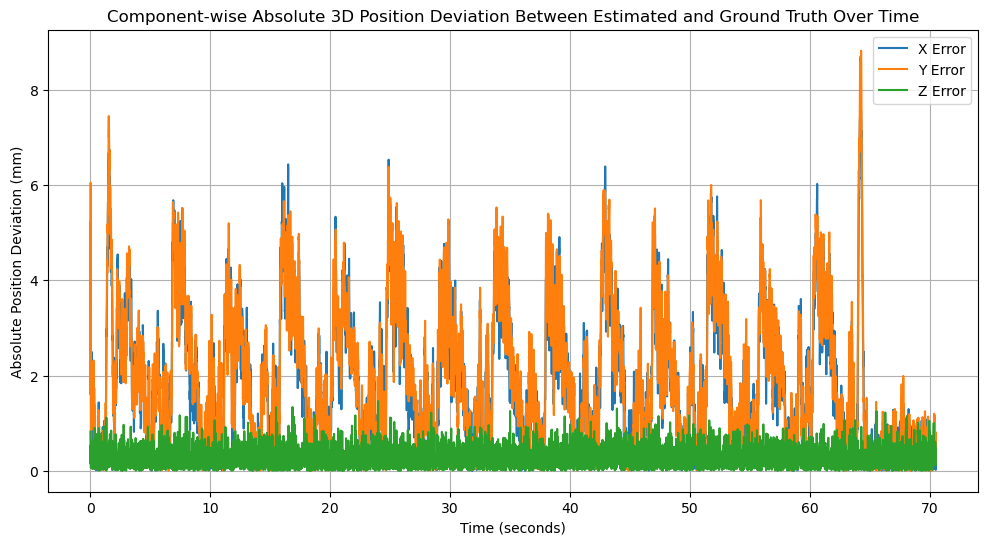

COMPONENT-WISE POSITION ERROR STATISTICS
Mean X Error = 0.001870 m (1.87 mm)
Mean Y Error = 0.001925 m (1.93 mm)
Mean Z Error = 0.000287 m (0.29 mm)

Maximum X Error = 0.008679 m (8.68 mm)
Maximum Y Error = 0.008824 m (8.82 mm)
Maximum Z Error = 0.001463 m (1.46 mm)


In [72]:
err_x = np.abs(X_est - X_gtrue)
err_y = np.abs(Y_est - Y_gtrue)
err_z = np.abs(Z_est - Z_gtrue)

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, err_x*1000, label='X Error')
plt.plot(time_inseconds, err_y*1000, label='Y Error')
plt.plot(time_inseconds, err_z*1000, label='Z Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Position Deviation (mm)")

plt.title("Component-wise Absolute 3D Position Deviation Between Estimated and Ground Truth Over Time")

plt.legend()
plt.grid(True)

plt.savefig("Figures/EKF_Position_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Position Error Statistics

# Mean Absolute Error
mean_x = np.mean(err_x)
mean_y = np.mean(err_y)
mean_z = np.mean(err_z)

# Maximum Absolute Error
max_x = np.max(err_x)
max_y = np.max(err_y)
max_z = np.max(err_z)

print("="*60)
print("COMPONENT-WISE POSITION ERROR STATISTICS")
print("="*60)

print(f"Mean X Error = {mean_x:.6f} m ({mean_x*1000:.2f} mm)")
print(f"Mean Y Error = {mean_y:.6f} m ({mean_y*1000:.2f} mm)")
print(f"Mean Z Error = {mean_z:.6f} m ({mean_z*1000:.2f} mm)")

print()

print(f"Maximum X Error = {max_x:.6f} m ({max_x*1000:.2f} mm)")
print(f"Maximum Y Error = {max_y:.6f} m ({max_y*1000:.2f} mm)")
print(f"Maximum Z Error = {max_z:.6f} m ({max_z*1000:.2f} mm)")

print("="*60)

- The component-wise absolute position deviation remains small throughout the complete trajectory, indicating that the Extended Kalman Filter provides accurate recursive position estimation.

- The mean absolute errors in the $X$ and $Y$ directions remain low, demonstrating consistent estimation performance in the horizontal plane despite the presence of turning motion.

- The $X$ and $Y$ components exhibit larger fluctuations than the $Z$ component because the horizontal motion is influenced by continuous changes in direction, introducing tangential prediction errors that arise from the constant-velocity motion model.

- The $Z$-direction error remains consistently small throughout the experiment since the vertical motion experiences minimal acceleration and closely satisfies the constant-velocity assumption adopted by the prediction model.

- Short-duration error peaks are observed primarily in the horizontal components during the transitions between straight and curved sections. These peaks correspond to temporary modelling errors caused by the unmodelled centripetal acceleration and are gradually corrected through successive recursive measurement updates.

- Unlike the Linear Kalman Filter, the Extended Kalman Filter processes the nonlinear Total Station measurements directly using the nonlinear measurement function and the Jacobian matrix. Consequently, the recursive measurement updates remain consistent with the sensor geometry, reducing the overall position deviations.

- The maximum deviations remain isolated and do not persist throughout the trajectory, indicating that the filter rapidly compensates for temporary prediction errors and maintains stable recursive estimation.

- The low mean absolute deviations together with the bounded maximum errors confirm that the implemented Extended Kalman Filter provides accurate, numerically stable, and physically consistent position estimation throughout the complete experiment.

## 4. Component wise Absolute deviation between estimated and ground truth 3D velocity over time

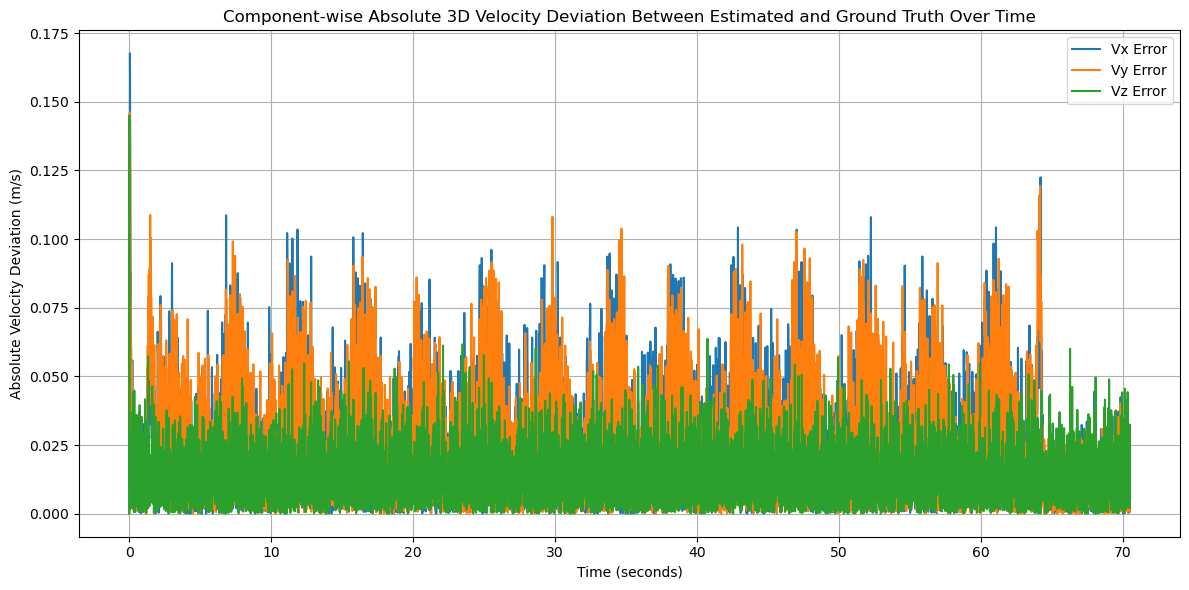

COMPONENT-WISE VELOCITY ERROR STATISTICS
Mean Vx Error = 0.025326 m/s
Mean Vy Error = 0.025382 m/s
Mean Vz Error = 0.013939 m/s

Maximum Vx Error = 0.167631 m/s at Epoch 5
Maximum Vy Error = 0.146155 m/s at Epoch 4
Maximum Vz Error = 0.144970 m/s at Epoch 1


In [73]:
err_vx = np.abs(Vx_est - vx_true)
err_vy = np.abs(Vy_est - vy_true)
err_vz = np.abs(Vz_est - vz_true)

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    err_vx,
    label='Vx Error')

plt.plot(
    time_inseconds,
    err_vy,
    label='Vy Error')

plt.plot(
    time_inseconds,
    err_vz,
    label='Vz Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Velocity Deviation (m/s)")
plt.title("Component-wise Absolute 3D Velocity Deviation Between Estimated and Ground Truth Over Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("Figures/EKF_Velocity_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Velocity Error Statistics
# Mean Absolute Error
mean_vx = np.mean(err_vx)
mean_vy = np.mean(err_vy)
mean_vz = np.mean(err_vz)

# Maximum Absolute Error
max_vx = np.max(err_vx)
max_vy = np.max(err_vy)
max_vz = np.max(err_vz)

# Epoch of Maximum Error
epoch_vx = np.argmax(err_vx)
epoch_vy = np.argmax(err_vy)
epoch_vz = np.argmax(err_vz)

print("="*60)
print("COMPONENT-WISE VELOCITY ERROR STATISTICS")
print("="*60)

print(f"Mean Vx Error = {mean_vx:.6f} m/s")
print(f"Mean Vy Error = {mean_vy:.6f} m/s")
print(f"Mean Vz Error = {mean_vz:.6f} m/s")

print()

print(f"Maximum Vx Error = {max_vx:.6f} m/s at Epoch {epoch_vx}")
print(f"Maximum Vy Error = {max_vy:.6f} m/s at Epoch {epoch_vy}")
print(f"Maximum Vz Error = {max_vz:.6f} m/s at Epoch {epoch_vz}")

print("="*60)

- The component-wise absolute velocity deviations remain small throughout the complete trajectory, indicating that the Extended Kalman Filter provides accurate recursive estimation of the target velocity despite the absence of direct velocity measurements.

- The mean absolute deviations in the $V_x$ and $V_y$ components remain low, showing consistent estimation of the horizontal velocity throughout the experiment.

- The horizontal velocity components exhibit larger fluctuations than the vertical component because the target continuously changes its direction of motion during the curved sections of the track. These changes introduce temporary tangential prediction errors that arise from the constant-velocity motion model.

- The $V_z$ component maintains the smallest absolute deviation throughout the experiment since the vertical motion experiences minimal dynamic variation and closely satisfies the constant-velocity assumption adopted by the prediction model.

- The largest velocity deviations occur during the initial recursive iterations, where the filter is still estimating the unknown initial velocity states from successive position measurements. As the recursive estimation progresses, the velocity deviations decrease and remain bounded throughout the remainder of the trajectory.

- Short-duration velocity error peaks are observed primarily in the horizontal components during the transitions between straight and curved motion. These peaks correspond to temporary modelling errors introduced by the unmodelled centripetal acceleration and are gradually corrected through successive measurement updates.

- The low mean absolute velocity deviations together with the bounded maximum errors demonstrate that the implemented Extended Kalman Filter provides stable, accurate, and physically consistent velocity estimation throughout the complete experiment.

## 5. Component Wise Cumulative RMSE for 3D position over time

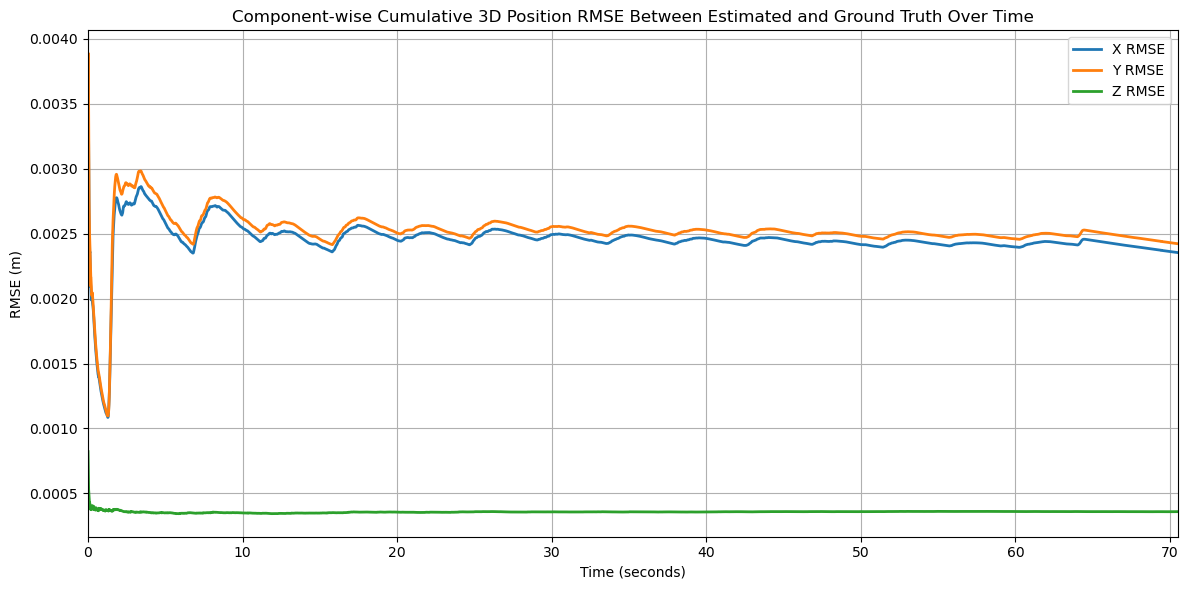

COMPONENT-WISE POSITION RMSE
RMSE X = 0.002355 m (2.35 mm)
RMSE Y = 0.002423 m (2.42 mm)
RMSE Z = 0.000360 m (0.36 mm)


In [74]:
# Component-wise Cumulative 3D Position RMSE

cum_rmse_x = np.zeros(len(X_est))
cum_rmse_y = np.zeros(len(Y_est))
cum_rmse_z = np.zeros(len(Z_est))

for k in range(1, len(X_est) + 1):

    cum_rmse_x[k-1] = np.sqrt(
        np.mean((X_est[:k] - X_gtrue[:k])**2))

    cum_rmse_y[k-1] = np.sqrt(
        np.mean((Y_est[:k] - Y_gtrue[:k])**2))

    cum_rmse_z[k-1] = np.sqrt(
        np.mean((Z_est[:k] - Z_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, cum_rmse_x,
         label='X RMSE',
         linewidth=2)

plt.plot(time_inseconds, cum_rmse_y,
         label='Y RMSE',
         linewidth=2)

plt.plot(time_inseconds, cum_rmse_z,
         label='Z RMSE',
         linewidth=2)

plt.xlabel("Time (seconds)")
plt.ylabel("RMSE (m)")

plt.title("Component-wise Cumulative 3D Position RMSE Between Estimated and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/EKF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Final Component-wise RMSE

rmse_x = cum_rmse_x[-1]
rmse_y = cum_rmse_y[-1]
rmse_z = cum_rmse_z[-1]

print("="*60)
print("COMPONENT-WISE POSITION RMSE")
print("="*60)

print(f"RMSE X = {rmse_x:.6f} m ({rmse_x*1000:.2f} mm)")
print(f"RMSE Y = {rmse_y:.6f} m ({rmse_y*1000:.2f} mm)")
print(f"RMSE Z = {rmse_z:.6f} m ({rmse_z*1000:.2f} mm)")

print("="*60)

- The cumulative position RMSE converges rapidly during the initial recursive iterations and gradually stabilizes, indicating that the Extended Kalman Filter quickly adapts to the system dynamics and produces stable state estimates.

- The $X$ and $Y$ position RMSE values initially exhibit larger variations because the filter is estimating the unknown system states while simultaneously correcting the nonlinear measurement residuals. As additional measurements are incorporated, the cumulative $X$ and $Y$ RMSE values gradually converge to nearly constant values, demonstrating consistent recursive estimation and filter convergence.

- The $X$ and $Y$ RMSE curves remain nearly identical throughout the experiment because both components experience similar horizontal dynamics and are equally influenced by the turning motion of the robot.

- The $Z$-direction RMSE remains significantly smaller than the horizontal components throughout the trajectory, indicating that the vertical motion closely satisfies the constant-velocity assumption and experiences minimal modelling error.

- Small oscillations are observed in the horizontal RMSE curves during the early stages of estimation. These oscillations correspond to temporary prediction errors introduced during the transitions between straight and curved motion and gradually diminish as the recursive estimation progresses.

- The absence of increasing RMSE trends or persistent oscillations confirms that the implemented Extended Kalman Filter remains numerically stable throughout the complete experiment. 

## 6. Overall 3D position RMSE over time ( Computed for Easier Comparison)

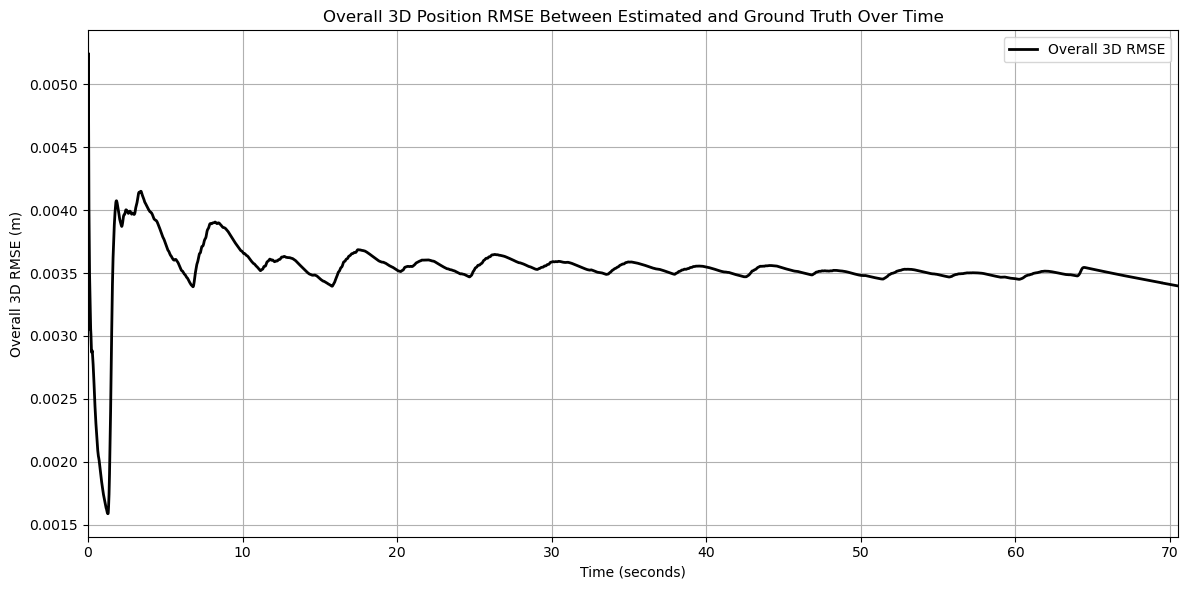

Overall 3D RMSE = 0.003398 m (3.40 mm)


In [75]:
# Overall 3D Position RMSE Over Time

cum_rmse_3d = np.zeros(len(X_est))

for k in range(1, len(X_est) + 1):

    error_squared = (
        (X_est[:k] - X_gtrue[:k])**2 +
        (Y_est[:k] - Y_gtrue[:k])**2 +
        (Z_est[:k] - Z_gtrue[:k])**2)

    cum_rmse_3d[k-1] = np.sqrt(
        np.mean(error_squared))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_3d,
    linewidth=2,
    color='black',
    label='Overall 3D RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Overall 3D RMSE (m)")

plt.title("Overall 3D Position RMSE Between Estimated and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/EKF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Overall 3D Position RMSE

overall_rmse = cum_rmse_3d[-1]

print("="*60)

print(f"Overall 3D RMSE = {overall_rmse:.6f} m ({overall_rmse*1000:.2f} mm)")

print("="*60)

## 7. Component wise Cumulative 3D velocity RMSE over time

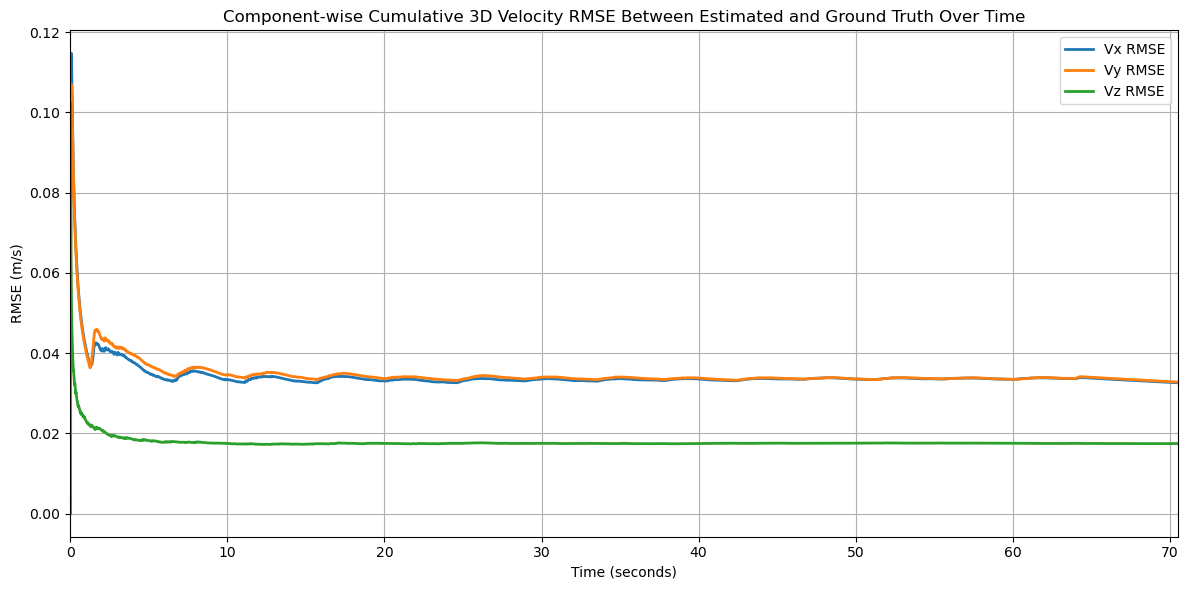

COMPONENT-WISE VELOCITY RMSE
RMSE Vx = 0.032615 m/s
RMSE Vy = 0.032794 m/s
RMSE Vz = 0.017479 m/s


In [76]:
cum_rmse_vx = np.zeros(len(Vx_est))
cum_rmse_vy = np.zeros(len(Vy_est))
cum_rmse_vz = np.zeros(len(Vz_est))

for k in range(1, len(Vx_est) + 1):

    cum_rmse_vx[k-1] = np.sqrt(
        np.mean((Vx_est[:k] - vx_true[:k])**2))

    cum_rmse_vy[k-1] = np.sqrt(
        np.mean((Vy_est[:k] - vy_true[:k])**2))

    cum_rmse_vz[k-1] = np.sqrt(
        np.mean((Vz_est[:k] - vz_true[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_vx,
    label='Vx RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_vy,
    label='Vy RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_vz,
    label='Vz RMSE',
    linewidth=2)

plt.xlabel("Time (seconds)")
plt.ylabel("RMSE (m/s)")

plt.title(
    "Component-wise Cumulative 3D Velocity RMSE Between Estimated and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/EKF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Final Component-wise Velocity RMSE

rmse_vx = cum_rmse_vx[-1]
rmse_vy = cum_rmse_vy[-1]
rmse_vz = cum_rmse_vz[-1]

print("="*60)
print("COMPONENT-WISE VELOCITY RMSE")
print("="*60)

print(f"RMSE Vx = {rmse_vx:.6f} m/s")
print(f"RMSE Vy = {rmse_vy:.6f} m/s")
print(f"RMSE Vz = {rmse_vz:.6f} m/s")

print("="*60)

- The cumulative velocity RMSE converges rapidly during the initial recursive iterations and gradually stabilizes, indicating that the Extended Kalman Filter quickly estimates the unknown velocity states and achieves stable recursive estimation.

- The $V_x$ and $V_y$ RMSE values initially decrease rapidly as the filter incorporates successive nonlinear measurements to refine the velocity estimates. As the estimation progresses, both components converge to nearly constant values, demonstrating stable filter convergence.

- The $V_x$ and $V_y$ RMSE curves remain almost identical throughout the experiment because both horizontal velocity components experience similar dynamic behaviour and are equally influenced by the turning motion of the robot.

- The $V_z$ RMSE remains significantly smaller than the horizontal velocity components since the vertical motion undergoes minimal acceleration and closely satisfies the constant-velocity assumption adopted by the prediction model.

- Small oscillations are observed during the initial estimation period while the filter is estimating the unknown initial velocity states. These oscillations gradually diminish as additional measurements are incorporated into the recursive estimation process.

- The cumulative velocity RMSE curves remain bounded and converge smoothly without oscillatory or divergent behaviour, confirming the numerical stability of the implemented Extended Kalman Filter.

- The low final component-wise velocity RMSE values demonstrate that the Extended Kalman Filter provides accurate, stable, and physically consistent estimation of the three-dimensional velocity throughout the complete experiment.

## 8. Overall 3D velocity RMSE over time ( Computed for Easier Comparison)

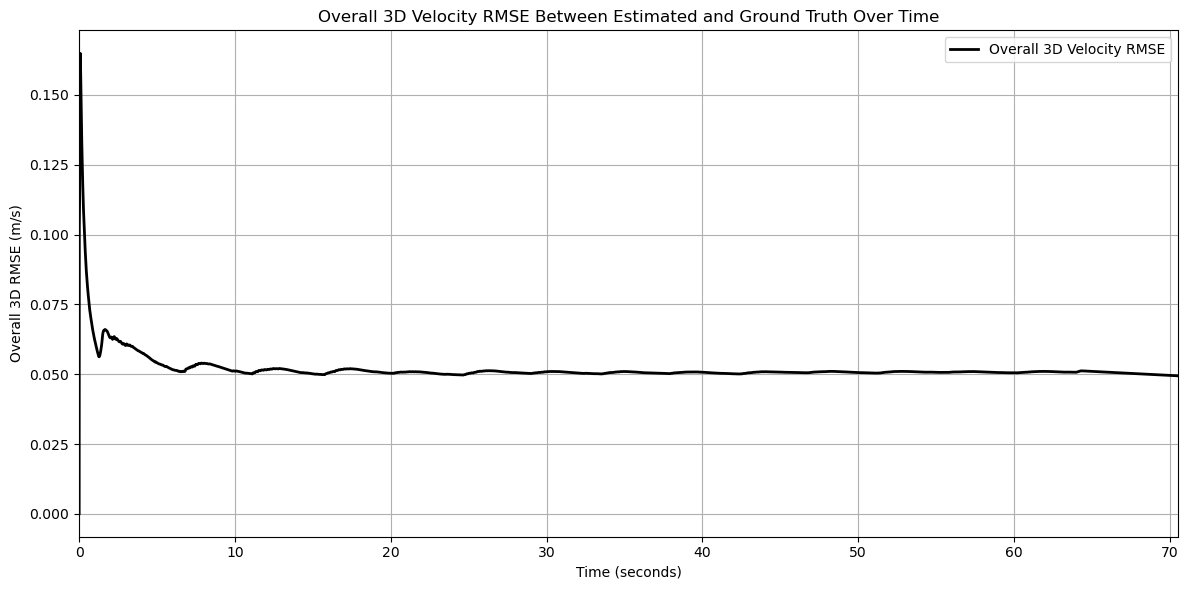

Overall 3D RMSE = 0.049444 m/s


In [77]:
cum_rmse_vel = np.zeros(len(Vx_est))

for k in range(1, len(Vx_est) + 1):

    error_squared = (
        (Vx_est[:k] - vx_true[:k])**2 +
        (Vy_est[:k] - vy_true[:k])**2 +
        (Vz_est[:k] - vz_true[:k])**2)

    cum_rmse_vel[k-1] = np.sqrt(
        np.mean(error_squared))


plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_vel,
    color='black',
    linewidth=2,
    label='Overall 3D Velocity RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Overall 3D RMSE (m/s)")

plt.title(
    "Overall 3D Velocity RMSE Between Estimated and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/EKF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()


# Overall 3D Velocity RMSE

overall_rmse_vel = cum_rmse_vel[-1]

print("="*60)
print(f"Overall 3D RMSE = {overall_rmse_vel:.6f} m/s")

print("="*60)

## The Constrained Extended Kalman Filter

The Constrained Extended Kalman Filter (CEKF) is an extension of the standard EKF that incorporates known physical or geometric constraints into the state estimation process. While the unconstrained EKF estimates the system states using only the process model and measurement information, the CEKF additionally ensures that the estimated states satisfy predefined constraints.

In this work, the object is known to move along a predefined path, and this prior knowledge is incorporated into the filter through geometric constraints. After each EKF update, the estimated position is projected onto the feasible region defined by the constraints. This correction prevents physically impossible estimates and improves the overall estimation accuracy.

## PROCEDURE
## 2D Trajectory plotting to find laps from Ground Truth

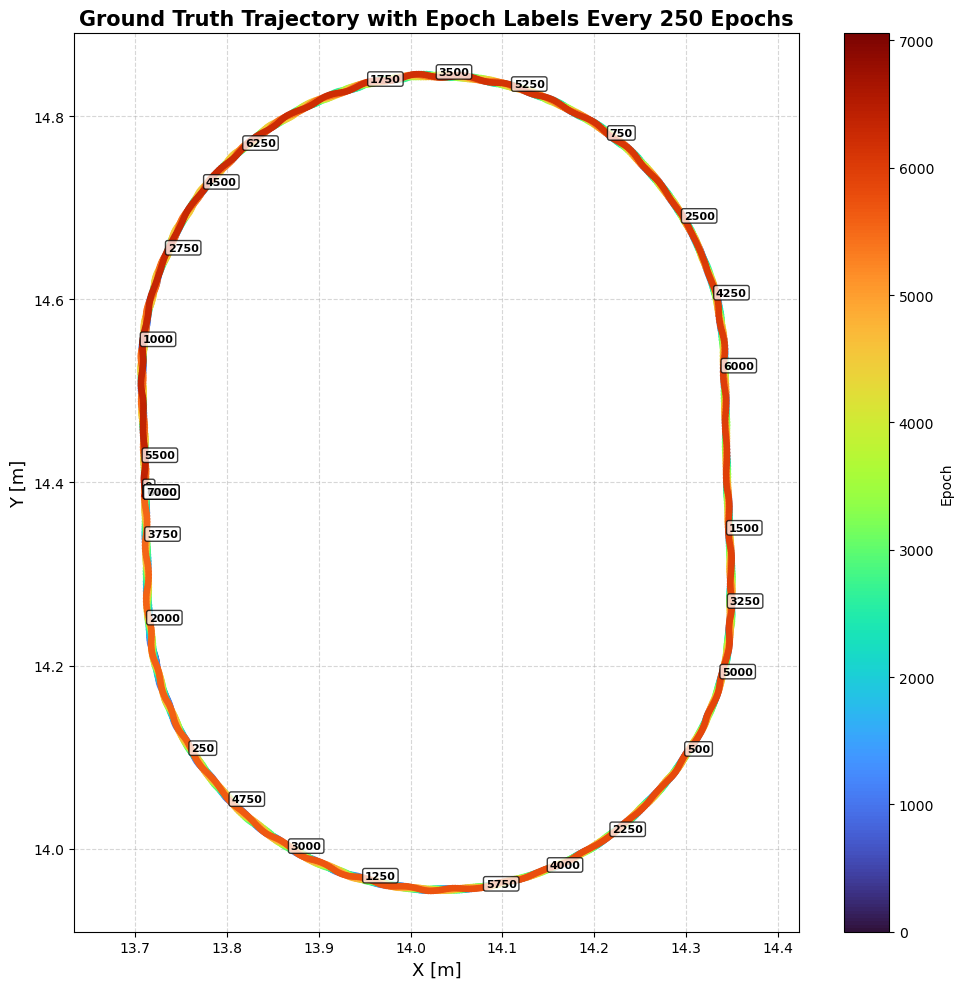

In [78]:
step = 250   # better understanding 
plt.figure(figsize=(10,10))

plt.plot(
    X_gtrue,
    Y_gtrue,
    color='lightgray',
    linewidth=2,
    zorder=1)

scatter = plt.scatter(
    X_gtrue,
    Y_gtrue,
    c=np.arange(len(X_gtrue)),
    cmap='turbo',
    s=15,
    zorder=2)

for i in range(0, len(X_gtrue), step):

    plt.text(
        X_gtrue[i],
        Y_gtrue[i],
        str(i),
        fontsize=8,
        color='black',
        weight='bold',
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            alpha=0.75,
            boxstyle='round,pad=0.2'))

plt.colorbar(scatter, label="Epoch")

plt.xlabel("X [m]", fontsize=13)
plt.ylabel("Y [m]", fontsize=13)

plt.title(
    f"Ground Truth Trajectory with Epoch Labels Every {step} Epochs",
    fontsize=15,
    fontweight='bold')

plt.axis('equal')

plt.grid(
    linestyle='--',
    alpha=0.5)

plt.tight_layout()

plt.show()

#### From the plot it can be understood that overlaps each other 7 times.

###  Lap Detection using Scipy.signal

This step is used to automatically identify the starting point of each lap in the ground-truth trajectory. Since `find_peaks()` detects maxima, the X-coordinate is first inverted so that the minimum X positions become maxima. The detected indices correspond to the beginning of each lap are used to divide the complete trajectory into individual laps for separate analysis and comparison. The `distance` parameter ensures that only one point is detected per lap, while the `prominence` parameter helps eliminate false detections caused by small fluctuations or noise.

In [79]:
from scipy.signal import find_peaks

# Invert X because find_peaks detects maxima
invX = -X_gtrue

# Detect minima
peaks, properties = find_peaks(
    invX,
    distance=800,     # roughly one lap apart
    prominence=0.2)   # adjust if necessary

print("Lap start indices:")
print(peaks)

Lap start indices:
[1019 1915 2802 3688 4580 5461]


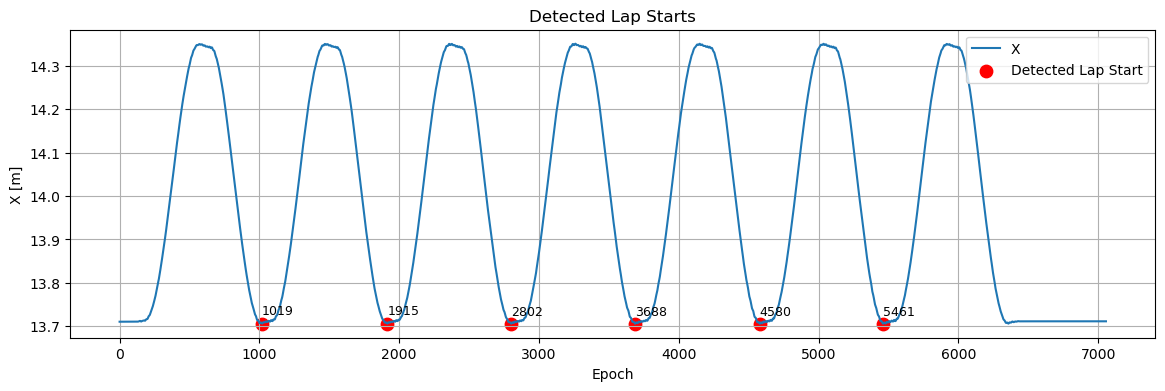

In [80]:
plt.figure(figsize=(14,4))

plt.plot(X_gtrue, label='X')

plt.scatter(
    peaks,
    X_gtrue[peaks],
    color='red',
    s=80,
    label='Detected Lap Start')

for p in peaks:
    plt.text(
        p,
        X_gtrue[p]+0.02,
        str(p),
        fontsize=9)

plt.xlabel("Epoch")
plt.ylabel("X [m]")

plt.title("Detected Lap Starts")
plt.grid(True)
plt.legend()
plt.show()

#### From the plotted lap peaks the second lap from 1019 to 1916 was choosen manually for further inspection.

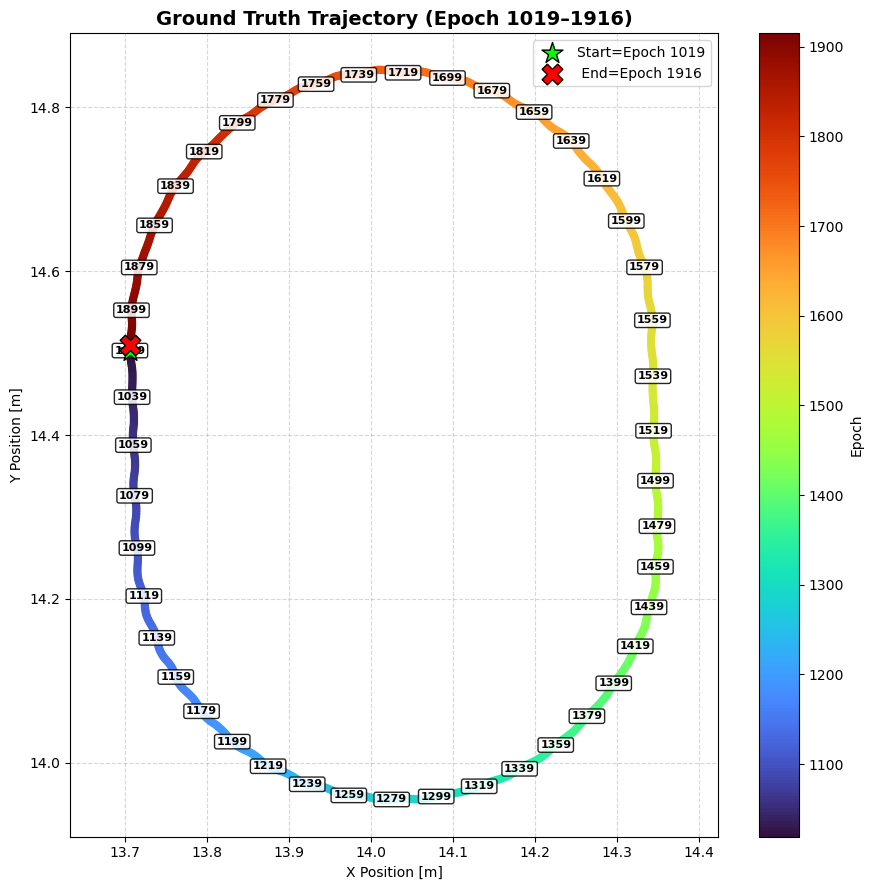

In [81]:
## Choosen lap- Second lap
lap_start = 1019
lap_end = 1916

X_lap = X_gtrue[lap_start:lap_end]
Y_lap = Y_gtrue[lap_start:lap_end]

step = 20      # Label every 20 epochs

plt.figure(figsize=(9,9))

# Trajectory
plt.plot(
    X_lap,
    Y_lap,
    color='lightgray',
    linewidth=2,
    zorder=1)

# Colour by epoch
scatter = plt.scatter(
    X_lap,
    Y_lap,
    c=np.arange(lap_start, lap_end),
    cmap='turbo',
    s=25,
    zorder=2)

# Epoch labels
for i in range(lap_start, lap_end, step):

    idx = i - lap_start

    plt.text(
        X_lap[idx],
        Y_lap[idx],
        str(i),
        fontsize=8,
        fontweight='bold',
        ha='center',
        va='center',
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            alpha=0.85,
            boxstyle='round,pad=0.2'),zorder=3)

# Start of first lap
plt.scatter(
    X_lap[0],
    Y_lap[0],
    color='lime',
    edgecolor='black',
    marker='*',
    s=250,
    label='Start=Epoch 1019',
    zorder=5)

# End of first lap
plt.scatter(
    X_lap[-1],
    Y_lap[-1],
    color='red',
    edgecolor='black',
    marker='X',
    s=220,
    label=' End=Epoch 1916',
    zorder=5)

# Colourbar
cbar = plt.colorbar(scatter)
cbar.set_label("Epoch")

plt.xlabel("X Position [m]")
plt.ylabel("Y Position [m]")

plt.title(
    "Ground Truth Trajectory (Epoch 1019–1916)",
    fontsize=14,
    fontweight='bold')

plt.axis("equal")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

## Identifying arc segments and calculating radii

After extracting one complete lap, the trajectory was visualized with epoch labels to identify the curved sections of the track. Based on visual inspection, approximate start and end points were selected for the two circular arcs. These values serve only as **initial estimates** and are not expected to exactly match the true arc boundaries.

In the next step, a geometric least-squares circle fitting method is applied to these initial segments. The fitting residuals are then used to refine the selected regions by removing points that do not belong to the circular arcs. This process produces more accurate arc boundaries and circle parameters for use in the constrained EKF.

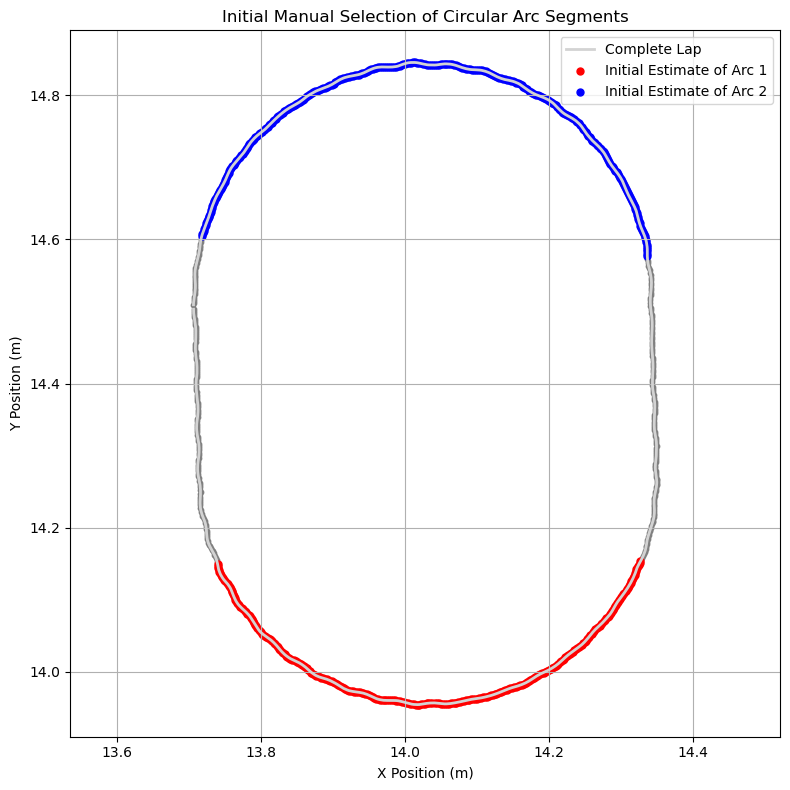

In [82]:
# Initial Arc Estimates by Manual Visual Inspection
# One complete lap
lap_start = 1019
lap_end   = 1916

X_lap = X_gtrue[lap_start:lap_end]
Y_lap = Y_gtrue[lap_start:lap_end]

# Initial estimates of the two circular arcs
P1_start = 1140
P1_end   = 1425

P2_start = 1570
P2_end   = 1880

# Convert global indices to lap indices
idx1 = np.arange(P1_start - lap_start,
                 P1_end   - lap_start)

idx2 = np.arange(P2_start - lap_start,
                 P2_end   - lap_start)

# Plot Initial Arc Estimates

plt.figure(figsize=(8,8))

# Complete lap trajectory
plt.plot(
    X_lap,
    Y_lap,
    color='lightgray',
    linewidth=2,
    label='Complete Lap')

# All trajectory points
plt.scatter(
    X_lap,
    Y_lap,
    s=10,
    color='gray')

# Initial estimate of Arc 1
plt.scatter(
    X_lap[idx1],
    Y_lap[idx1],
    color='red',
    s=25,
    label='Initial Estimate of Arc 1')

# Initial estimate of Arc 2
plt.scatter(
    X_lap[idx2],
    Y_lap[idx2],
    color='blue',
    s=25,
    label='Initial Estimate of Arc 2')

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")

plt.title("Initial Manual Selection of Circular Arc Segments")

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

##  Calculation of Circle centre XC1,YC1 and Radius R1 of P1 arc segment

In [83]:
#Extract the selected Arc segment
# Convert the epoch numbers into indices relative to the
# extracted lap and obtain the coordinates of the selected
# circular arc.
# Convert global epochs to local lap indices
P1_index = np.arange(
    P1_start - lap_start,
    P1_end   - lap_start)

# Extract the corresponding coordinates
P1_x = X_lap[P1_index]
P1_y = Y_lap[P1_index]

# Epoch values (used later for residual plots)
P1_epoch = np.arange(P1_start, P1_end)

print("Number of selected points :", len(P1_x))

Number of selected points : 285


In [84]:
# Estimate initial Circle/centroid

init_Xc = np.mean(P1_x)
init_Yc = np.mean(P1_y)

init_R = np.mean(np.sqrt((P1_x - init_Xc)**2 
                                 +(P1_y - init_Yc)**2))

init_guess = [init_Xc,init_Yc,init_R]

                            
print("Initial Circle Estimate")
print("-----------------------")
print(f"Centre X : {init_Xc:.6f}")
print(f"Centre Y : {init_Yc:.6f}")
print(f"Radius   : {init_R:.6f}")

Initial Circle Estimate
-----------------------
Centre X : 14.034206
Centre Y : 14.025050
Radius   : 0.182558


#### The initial circle centres and radius of P1 arc segment are found but must be refined to remove unwanted epochs by a circle fitting Method. The circle fitting we implemented is Geometric Least square method.

##  Geometric LS 

The initial arc boundaries are selected manually and may include points that do not belong to the circular section. Geometric Least Squares (GLS) is used to accurately fit a circle to these points by minimizing the geometric distance between each point and the fitted circle. This produces reliable estimates of the circle center and radius while reducing the effect of small measurement errors. The fitted circle is then used to refine the arc boundaries by identifying and removing points that do not satisfy the circular model.Rather than defining the least squares function,it was directly imported from the scipy library.

In [85]:
from scipy.optimize import least_squares
#functions
#parameters=[Xc,Yc,R]
#x,y= Coordinate of mesaured points or ground truth x and y coordinates

#Function1: used to calculate all the errors/residuals so that LC can minimize the error.
def circle_residuals(parameter,x,y):
    xc, yc, R = parameter
    
#compute the distance from every point to the guessed centre.
    distance = np.sqrt((x-xc)**2 +(y-yc)**2)
#Error   
    residual = distance-R
    return residual


In [86]:
def fit_circle_geometric(init_guess, x, y):

    # Perform nonlinear least-squares optimisation
    result = least_squares(
        circle_residuals,      # Residual function
        init_guess,            # Initial guess
        args=(x, y))            # Additional arguments

    # Extract the optimized circle parameters
    Xc_final, Yc_final, R_final = result.x

    return Xc_final, Yc_final, R_final, result

# Fit the circle to the selected P1 arc
Xc_final, Yc_final, R_final, result = fit_circle_geometric(init_guess,P1_x,P1_y)


print("Optimized Circle Parameters after Geometric LS")
print("----------------------------------------------")
print(f"Centre X : {Xc_final:.6f}")
print(f"Centre Y : {Yc_final:.6f}")
print(f"Radius   : {R_final:.6f}")

Optimized Circle Parameters after Geometric LS
----------------------------------------------
Centre X : 14.032264
Centre Y : 14.273961
Radius   : 0.318500


## Visualize the Geometric LS Circle Fit

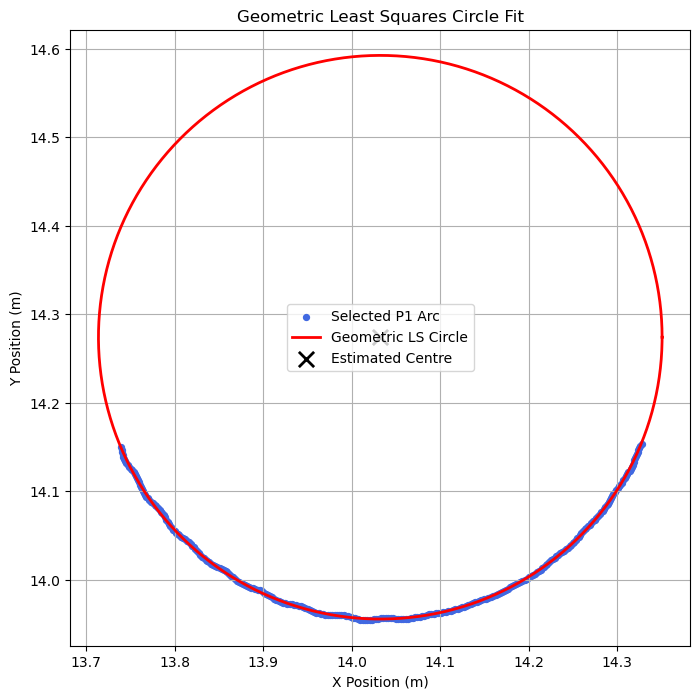

In [87]:
# Generate points to draw the fitted circle
theta = np.linspace(0, 2*np.pi, 400)

circle_x = Xc_final + R_final * np.cos(theta)
circle_y = Yc_final + R_final * np.sin(theta)

plt.figure(figsize=(8,8))

# Selected arc points
plt.scatter(
    P1_x,
    P1_y,
    s=18,
    color='royalblue',
    label='Selected P1 Arc')

# Fitted circle
plt.plot(
    circle_x,
    circle_y,
    color='red',
    linewidth=2,
    label='Geometric LS Circle')

# Estimated centre
plt.scatter(
    Xc_final,
    Yc_final,
    marker='x',
    color='black',
    s=120,
    linewidth=2,
    label='Estimated Centre')

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Geometric Least Squares Circle Fit")

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()

## Residual(Geometric Error) Calculation and Arc Refinement

After obtaining the optimized circle parameters using Geometric Least Squares, the geometric residual of each point is computed. The residual is defined as the difference between the distance of a point from the fitted circle centre and the estimated radius.

A residual close to zero indicates that the point lies on the fitted circle, whereas a larger residual indicates that the point does not belong to the circular arc. Since the initial arc boundaries were selected manually, they may include points from the straight sections or transition regions. By analysing the residuals, these unwanted points can be identified and removed.

The circle is then fitted again using only the refined set of points. This second fitting step produces more accurate estimates of the circle centre, radius, and arc boundaries, which are later used as geometric constraints in the constrained EKF.

In [88]:
#Residual calculation until reaches 0

geo_distance = np.sqrt((P1_x - Xc_final)**2 +(P1_y - Yc_final)**2)

# Geometric residual
geo_residual = geo_distance - R_final

#Compute RMSE
rmse = np.sqrt(np.mean(geo_residual**2))

print("Root Mean Square Error (RMSE)")
print("-----------------------------")
print(f"RMSE = {rmse:.6f} m")


Root Mean Square Error (RMSE)
-----------------------------
RMSE = 0.000896 m


## Residual-Based Arc Refinement

After fitting the initial circle using Geometric Least Squares, the geometric residual of each point was calculated.

The Root Mean Square Error (RMSE) of the residuals was then computed to measure the overall fitting error. A threshold equal to **2 × RMSE** was selected to distinguish valid arc points from outliers. Points with residuals satisfying

$$[
|e_i| < 2 \times \mathrm{RMSE}
]$$

were retained, while points with larger residuals were discarded. Since most large residuals occur near the beginning and end of the manually selected arc, this process automatically removes transition points between the straight and curved sections.

Finally, the circle was fitted again using only the retained points, resulting in more accurate estimates of the circle centre, radius, and arc boundaries. These refined circle parameters were then used to define the geometric constraints for the constrained EKF.

In [89]:
#Refining the centre/radius values of p1
# Residual threshold
threshold = 2 * rmse

print(f"Residual Threshold = ±{threshold:.6f} m")

# Keep only points whose residual is within the threshold
inlier_mask = np.abs(geo_residual) < threshold

# Refined arc coordinates
P1_x_refined = P1_x[inlier_mask]
P1_y_refined = P1_y[inlier_mask]

# Corresponding epochs
P1_epoch_refined = P1_epoch[inlier_mask]

Residual Threshold = ±0.001793 m


In [90]:
print(len(P1_x))
print(len(P1_x_refined))

285
283


#### Two epochs were ommited.

In [91]:
#Refined values of P1
Xc_refined, Yc_refined, R_refined, result = fit_circle_geometric(
    init_guess,
    P1_x_refined,
    P1_y_refined)

print("Final Circle Parameters")
print("-----------------------")

print(f"Centre X : {Xc_refined:.6f}")
print(f"Centre Y : {Yc_refined:.6f}")
print(f"Radius   : {R_refined:.6f}")

Final Circle Parameters
-----------------------
Centre X : 14.032232
Centre Y : 14.274026
Radius   : 0.318565


In [92]:
# Distance from refined circle centre
distance_final = np.sqrt(
    (P1_x_refined - Xc_refined)**2 +
    (P1_y_refined - Yc_refined)**2)

# Final residuals
residual_final = distance_final - R_refined

rmse_final = np.sqrt(
    np.mean(residual_final**2))

print("Initial RMSE :", rmse)
print("Final RMSE   :", rmse_final)

Initial RMSE : 0.0008962862044497174
Final RMSE   : 0.0008847030701946391


#### The residual-based refinement successfully improved the accuracy of the fitted circle by removing points that did not closely follow the circular arc.The RMSE decreased from **0.000896 m** to **0.000885 m** after refinement, indicating a better agreement between the trajectory points and the fitted circle.                      

#### Although the improvement is small (about 0.012 mm), this is expected because your manually selected P₁ segment was already very accurate. The refinement process confirmed that almost all selected points belonged to the circular arc, so only a very small adjustment of the circle parameters was required.



## Calculation of Centre XC2,YC2 and Radius R2 of P2


In [93]:
# Extract the Second Arc (P2)

# Convert global epochs to local lap indices
P2_index = np.arange(
    P2_start - lap_start,
    P2_end - lap_start)

# Extract P2 coordinates
P2_x = X_lap[P2_index]
P2_y = Y_lap[P2_index]

# Corresponding epochs
P2_epoch = np.arange(P2_start, P2_end)

print("Number of P2 points:", len(P2_x))

# Initial Circle Estimate for P2

# Initial centre (centroid)
init_Xc2 = np.mean(P2_x)
init_Yc2 = np.mean(P2_y)

# Initial radius
init_R2 = np.mean(
    np.sqrt(
        (P2_x - init_Xc2)**2 +
        (P2_y - init_Yc2)**2))

# Initial parameter vector
init_guess2 = [
    init_Xc2,
    init_Yc2,
    init_R2]

print("Initial Circle Estimate (P2)")
print("----------------------------")
print(f"Centre X : {init_Xc2:.6f}")
print(f"Centre Y : {init_Yc2:.6f}")
print(f"Radius   : {init_R2:.6f}")

# Geometric Least Squares Fit (P2)

Xc2, Yc2, R2, result = fit_circle_geometric(
    init_guess2,
    P2_x,
    P2_y)

print("Optimized Circle Parameters after Geometric LS (P2)")
print("---------------------------------------------------")
print(f"Centre X : {Xc2:.6f}")
print(f"Centre Y : {Yc2:.6f}")
print(f"Radius   : {R2:.6f}")

# Residual Analysis (P2)

# Distance from fitted centre
geo_distance2 = np.sqrt(
    (P2_x - Xc2)**2 +
    (P2_y - Yc2)**2)

# Geometric residual
geo_residual2 = geo_distance2 - R2

# Compute RMSE (P2)

rmse2 = np.sqrt(
    np.mean(
        geo_residual2**2))

# Refine Centre/radius of P2
threshold2 = 2 * rmse2

mask2 = np.abs(geo_residual2) < threshold2

P2_x_refined = P2_x[mask2]
P2_y_refined = P2_y[mask2]
P2_epoch_refined = P2_epoch[mask2]

print("Original points :", len(P2_x))
print("Refined points  :", len(P2_x_refined))

# Final Geometric LS Fit (P2)

Xc2_final, Yc2_final, R2_final, result = fit_circle_geometric(
    init_guess2,
    P2_x_refined,
    P2_y_refined)

print("Final Circle Parameters (P2)")
print("----------------------------")
print(f"Centre X : {Xc2_final:.6f}")
print(f"Centre Y : {Yc2_final:.6f}")
print(f"Radius   : {R2_final:.6f}")

# Final RMSE (P2)

distance2_final = np.sqrt(
    (P2_x_refined - Xc2_final)**2 +
    (P2_y_refined - Yc2_final)**2)

residual2_final = distance2_final - R2_final

rmse2_final = np.sqrt(
    np.mean(residual2_final**2))

print("Initial RMSE :", rmse2)
print("Final RMSE   :", rmse2_final)

Number of P2 points: 310
Initial Circle Estimate (P2)
----------------------------
Centre X : 14.027405
Centre Y : 14.754913
Radius   : 0.203752
Optimized Circle Parameters after Geometric LS (P2)
---------------------------------------------------
Centre X : 14.025774
Centre Y : 14.527408
Radius   : 0.316317
Original points : 310
Refined points  : 303
Final Circle Parameters (P2)
----------------------------
Centre X : 14.025753
Centre Y : 14.527224
Radius   : 0.316399
Initial RMSE : 0.000990706488301756
Final RMSE   : 0.000942824974815591


#### During the refinement process, **303** out of the original **310** points were retained, while **7** points with large residuals were removed as outliers. The reduction in RMSE confirms that the residual-based refinement effectively removed transition points and improved the accuracy of the fitted circle. The refined circle parameters obtained for P2 are subsequently used as geometric constraints in the constrained EKF.

## Final Estimated Circle Parameters



$$
\begin{array}{|c|c|c|}
\hline
\textbf{Parameter} & \mathbf{P_1} & \mathbf{P_2} \\
\hline
\textbf{Initial Centre }(X_c^{(0)},Y_c^{(0)}) &
(14.034206,\;14.025050) &
(14.029963,\;14.495684) \\
\hline
\textbf{Initial Radius }R^{(0)} &
0.182558 &
0.178786 \\
\hline
\textbf{Final Centre }(X_c,Y_c) &
(14.032232,\;14.274026) &
(14.025753,\;14.527224) \\
\hline
\textbf{Final Radius }R &
0.318565 &
0.316399 \\
\hline
\textbf{Initial RMSE (m)} &
0.000896 &
0.000991 \\
\hline
\textbf{Final RMSE (m)} &
0.000885 &
0.000943 \\
\hline
\textbf{Original Points} &
285 &
310 \\
\hline
\textbf{Refined Points} &
283 &
303 \\
\hline
\end{array}
$$

In [94]:
# Final circle parameters obtained using the Geometric LS circle fit.

# ---------- First Circular Arc (P1) ----------

Xc1 = 14.032232
Yc1 = 14.274026
R1  = 0.318565

# ---------- Second Circular Arc (P2) ----------

Xc2 = 14.025774
Yc2 = 14.527408
R2  = 0.316317

##  Defining the circle equation as Constraint equation

$$
(x-14.032232)^2+(y-14.274026)^2-(0.318565)^2=0
$$

$$
(x-14.025774)^2+(y-14.527408)^2-(0.316317)^2=0
$$

## Circular Constraint Function

In the constrained EKF, the robot is known to move along a circular path in the curved sections of the trajectory. This prior knowledge is introduced into the filter using a circular constraint. For a circle with centre $(X_c,Y_c)$ and radius $R$, every point on the circle satisfies

$$
(x-X_c)^2+(y-Y_c)^2=R^2.
$$

The constraint function is therefore defined as

$$
h(x,y)=(x-X_c)^2+(y-Y_c)^2-R^2.
$$

The value of the constraint function indicates whether the estimated position satisfies the circular constraint:

- If $h(x,y)=0$, the estimated point lies exactly on the fitted circle and no correction is required.
- If $h(x,y)\neq0$, the estimated point does not lie on the circle, and the constrained EKF projects the estimate back onto the feasible circular path.

Thus, the constraint function measures the geometric error between the estimated position and the fitted circle.

## PROCEDURE

In [95]:
# Circular Constraint Function (h)

#tells if the estimated points x and y lies on the fitted circle
#if yes no projection we got the answer
#if no project until we get true
#Tells the error how far you are from the fitting
def circle_constraint(x, y, Xc, Yc, R):

    h_circle = ((x - Xc)**2 +(y - Yc)**2 -R**2)

    return h_circle
    


## Constraint Jacobian

Differentiating the constraint function

$$
h(x,y)=(x-X_c)^2+(y-Y_c)^2-R^2
$$

with respect to the state variables gives

$$ \mathbf{H}_c= \begin{bmatrix} 2(x-X_c) & 2(y-Y_c) & 0 & 0 & 0 & 0 \end{bmatrix}$$

The Jacobian provides the direction in which the estimated state should be corrected so that it satisfies the circular constraint during the projection step of the constrained EKF.

In [96]:
# Constraint Jacobian (H)
# Computes the Jacobian of the circular constraint.
#Tells the direction only for x and y

def constraint_jacobian(state, Xc, Yc):

    # Extract the position estimate
    x = state[0]
    y = state[1]

    # Compute the Jacobian
    Hc = np.array([[
        2 * (x - Xc),
        2 * (y - Yc),
        0,
        0,
        0,
        0
    ]])

    return Hc


## CEKF using Projection Method

The projection method is applied after the EKF update to ensure that the estimated state satisfies the circular constraint. If the estimated position already lies on the fitted circle, no correction is required. Otherwise, the estimate is projected onto the constraint surface using the projection gain matrix.

The projection requires both the constraint function, $h(x)$, and its Jacobian, $\mathbf{H}_c$.

- The constraint function $h(x)$ measures the constraint violation, that is, how far the estimated point is from the fitted circle.
- The Jacobian $\mathbf{H}_c$ provides the direction in which the state should be corrected to satisfy the constraint.
- The projection gain $\mathbf{K}_c$ determines the magnitude of the correction based on the predicted state uncertainty.

If

$$
h(x)>0,
$$

the estimated point lies outside the circle. The projection moves the estimate inward toward the circular path.

If

$$
h(x)<0,
$$

the estimated point lies inside the circle. The projection moves the estimate outward toward the circular path.

After projection, the corrected state satisfies the geometric constraint while remaining consistent with the EKF estimate, resulting in more accurate and physically valid state estimates.

In [97]:
def projection_gain(Hc, Q_xx_plus):

    # Compute the projection gain
    Kc = (
        Q_xx_plus
        @ Hc.T
        @ np.linalg.inv(
            Hc @ Q_xx_plus @ Hc.T
        ))
    return Kc


In [98]:
def project_state(X_k_plus, Kc, h):

    correction = Kc.flatten() * h

    X_CEKF = X_k_plus - correction

    return X_CEKF

In [99]:
# Covariance Projection

def project_covariance(Q_xx_plus, Kc, Hc):

    # Identity matrix (6 × 6)
    I6 = np.eye(6)

    # Project the covariance
    Q_CEKF = (I6 - Kc @ Hc) @ Q_xx_plus

    return Q_CEKF

In [100]:
# Constrained EKF loop

#prediction step begins......
N = len(obsrv)

estimates_cekf = np.zeros((N,6))
X_plus_history_cekf = np.zeros((N, 6))
Q_plus_history_cekf = np.zeros((N, 6, 6))


X_k = np.array([
    X0,
    Y0,
    Z0,
    0,
    0,
    0])

# Reseting Initial Covariance.....

Q_xx = np.diag([
    Q_XYZ0[0,0],
    Q_XYZ0[1,1],
    Q_XYZ0[2,2],
    1,
    1,
    1])

estimates_cekf[0] = X_k
X_plus_history_cekf[0] = X_k
Q_plus_history_cekf[0] = Q_xx

I6 = np.eye(6)

# Start Timing

start_time = time.perf_counter()


for k in range(1, N):

    X_k_minus = Phi_k @ X_k

    Q_xx_minus = (Phi_k@ Q_xx@ Phi_k.T + Q_ww)

#observation vector
    l_k = np.array([obsrv["H_radian"].iloc[k],
                    obsrv["V_radian"].iloc[k],
                    obsrv["D_m"].iloc[k]])

#Observation/measurement covariance
    
    sigma_H = np.deg2rad(0.0014) # given 

    sigma_V = np.deg2rad(0.0014) #given

    sigma_D = (0.0025 *obsrv["D_m"].iloc[k]+ 0.0025) #given

    Q_HVD = np.diag([sigma_H**2,
                             sigma_V**2,
                             sigma_D**2])   
#Q_ll not needed.
    
#initiate the jacobian EKF

    H_k= H_jacobian(X_k_minus)

#Update step begins....
    
#Innovation(Residual)
        
    I = l_k - h(X_k_minus)
    
# Horizontal angle wrapping

    I[0] = np.arctan2(np.sin(I[0]),np.cos(I[0]))
    
# Innovation Covariance
    
    S = (H_k@ Q_xx_minus@ H_k.T+Q_HVD)


#h(x) gives predicted measurements, while H_k gives the measurement sensitivities needed for covariance propagation.

# Kalman Gain
   

    K = (Q_xx_minus@ H_k.T@ np.linalg.inv(S))

#corrected step(posteriori)

    X_k_plus = (X_k_minus+K @ I)

    
# Covariance Update
    
    Q_xx_plus = (I6- K @ H_k) @ Q_xx_minus

    
    # Check whether this point belongs to P1
    
    if P1_start <= k <= P1_end:

        Xc = Xc1
        Yc = Yc1
        R  = R1

    elif P2_start <= k <= P2_end:

        Xc = Xc2
        Yc = Yc2
        R  = R2
    
    # Straight road
    
    else:
        
        Xc = None
        Yc = None
        R = None

    # -----------------------------------------
    # Apply Projection CEKF
    # -----------------------------------------

    if Xc is not None:

        # Constraint before projection
        h_before = circle_constraint(
            X_k_plus[0],
            X_k_plus[1],
            Xc,
            Yc,
            R)

        # Constraint Jacobian
        Hc = constraint_jacobian(
            X_k_plus,
            Xc,
            Yc)

        # Projection gain
        Kc = projection_gain(
            Hc,
            Q_xx_plus)

        # Project state
        X_CEKF = project_state(
            X_k_plus,
            Kc,
            h_before)

        # Constraint after projection
        h_after = circle_constraint(
            X_CEKF[0],
            X_CEKF[1],
            Xc,
            Yc,
            R)

        # Project covariance
        Q_CEKF = project_covariance(
            Q_xx_plus,
            Kc,
            Hc)

        # Replace EKF estimate
        X_k_plus = X_CEKF
        Q_xx_plus = Q_CEKF


    X_plus_history_cekf[k] = X_k_plus

    Q_plus_history_cekf[k] = Q_xx_plus

    estimates_cekf[k] = X_k_plus   

# Update for Next Epoch

    X_k = X_k_plus

    Q_xx = Q_xx_plus
    
# Stop Timing

    end_time = time.perf_counter()

    computation_time = end_time - start_time
    
X_est_cekf = estimates_cekf[:,0]

Y_est_cekf = estimates_cekf[:,1]

Z_est_cekf = estimates_cekf[:,2]

Vx_est_cekf = estimates_cekf[:,3]

Vy_est_cekf = estimates_cekf[:,4]

Vz_est_cekf = estimates_cekf[:,5]

print("="*60)
print("COMPUTATION TIME FOR PROJECTION BASED EKF")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")

print("="*60)


COMPUTATION TIME FOR PROJECTION BASED EKF
Total Time : 0.732310 s
Average Time per Epoch : 0.00010379 s
Average Time per Epoch : 0.1038 ms


## OBSERVATIONS
## 1. Comparison between the projected CEKF and Unconstrained EKF at selected lap

In [101]:
test_epochs = [1140, 1300, 1425, 1570, 1725, 1880]

labels = ["X","Y","Z","Vx","Vy","Vz"]

for k in test_epochs:

    print("\n" + "="*70)
    print(f"Epoch : {k}")
    print("="*70)

    for i in range(6):

        print(f"{labels[i]:<3} : "
              f"EKF  = {X_plus_history_ucekf[k][i]:>12.6f}    "
              f"CEKF = {X_plus_history_cekf[k][i]:>12.6f}")


Epoch : 1140
X   : EKF  =    13.736166    CEKF =    13.739064
Y   : EKF  =    14.146331    CEKF =    14.149313
Z   : EKF  =     0.160461    CEKF =     0.160495
Vx  : EKF  =     0.067168    CEKF =     0.081457
Vy  : EKF  =    -0.275889    CEKF =    -0.261312
Vz  : EKF  =    -0.016019    CEKF =    -0.015858

Epoch : 1300
X   : EKF  =    14.079768    CEKF =    14.081736
Y   : EKF  =    13.957389    CEKF =    13.959331
Z   : EKF  =     0.162550    CEKF =     0.162572
Vx  : EKF  =     0.231071    CEKF =     0.226868
Vy  : EKF  =     0.036057    CEKF =     0.035542
Vz  : EKF  =     0.001887    CEKF =     0.001843

Epoch : 1425
X   : EKF  =    14.329994    CEKF =    14.327412
Y   : EKF  =    14.156107    CEKF =    14.154225
Z   : EKF  =     0.161423    CEKF =     0.161400
Vx  : EKF  =     0.150919    CEKF =     0.066382
Vy  : EKF  =     0.206700    CEKF =     0.173241
Vz  : EKF  =    -0.015446    CEKF =    -0.015996

Epoch : 1570
X   : EKF  =    14.337705    CEKF =    14.337931
Y   : EKF  = 

#### The selected epochs correspond to different locations along the two circular arcs where the geometric constraint is applied.
#### The position coordinates ($X$, $Y$, and $Z$) change only slightly after projection, indicating that the unconstrained EKF estimates are already close to the fitted circular path. 
#### The largest corrections occur in the $X$ and $Y$ coordinates because the circular constraint acts only on the horizontal plane.
#### The $Z$ coordinate changes very little since it is not included in the circular constraint.The velocity components ($V_x$ and $V_y$) are also modified after projection to maintain consistency between the corrected position and the estimated motion along the circular trajectory.
#### The $V_z$ component remains almost unchanged because the geometric constraint does not directly affect the vertical motion. 
#### Overall, the constrained EKF makes small but meaningful corrections to the estimated states, ensuring that the trajectory remains physically consistent with the fitted circular path while preserving the overall EKF estimation accuracy.

## 2. Final 2D constrained estimation vs Ground truth trajectory

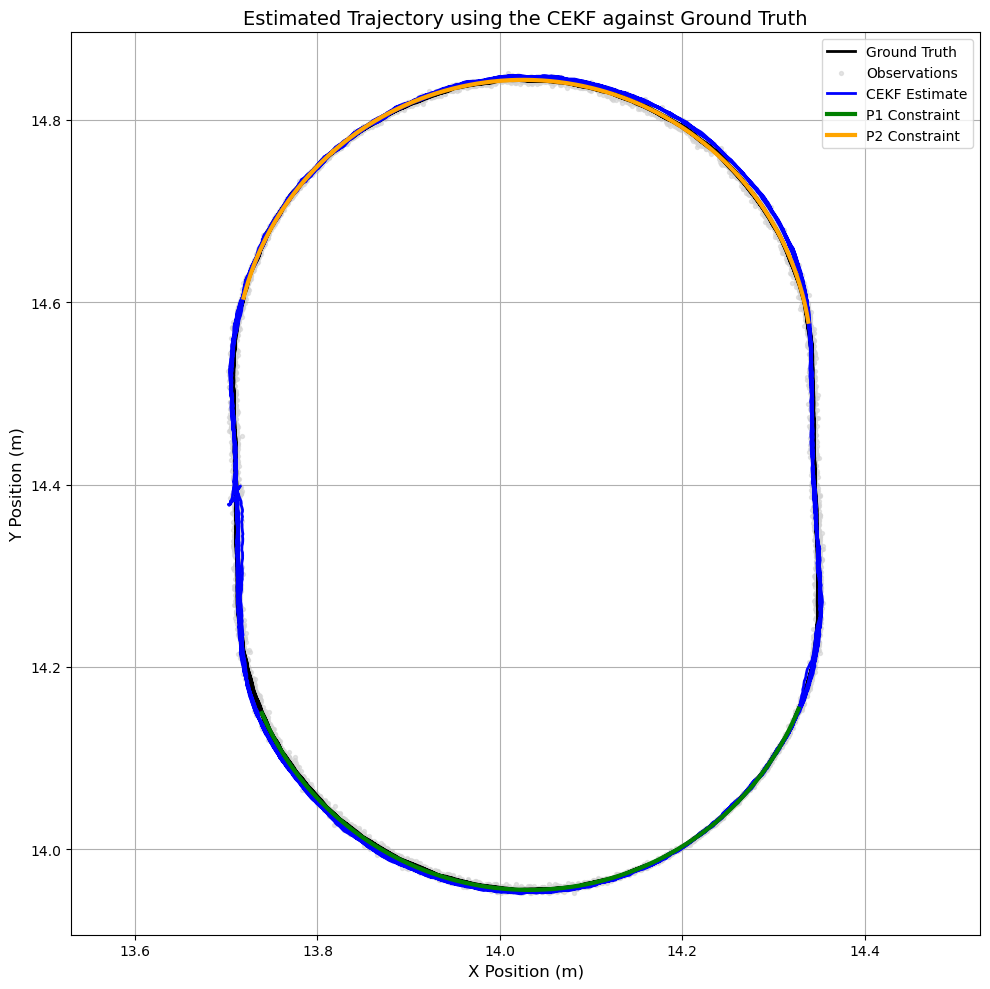

In [102]:
# Final 2D Estimated Trajectory using the Constrained EKF (CEKF)
plt.figure(figsize=(10, 10))

# Ground Truth
plt.plot(
    X_gtrue,
    Y_gtrue,
    color="black",
    linewidth=2,
    label="Ground Truth")

# Cartesian Observations
plt.scatter(
    obsrv["X_obsrv_cart"],
    obsrv["Y_obsrv_cart"],
    s=8,
    color="lightgray",
    alpha=0.6,
    label="Observations")

# Complete CEKF Trajectory
plt.plot(
    X_est_cekf,
    Y_est_cekf,
    color="blue",
    linewidth=2,
    label="CEKF Estimate")

# Highlight P1 Arc
plt.plot(
    X_est_cekf[P1_start:P1_end+1],
    Y_est_cekf[P1_start:P1_end+1],
    color="green",
    linewidth=3,
    label="P1 Constraint")

# Highlight P2 Arc
plt.plot(
    X_est_cekf[P2_start:P2_end+1],
    Y_est_cekf[P2_start:P2_end+1],
    color="orange",
    linewidth=3,
    label="P2 Constraint")

# Formatting
plt.xlabel("X Position (m)", fontsize=12)

plt.ylabel("Y Position (m)", fontsize=12)

plt.title(
    "Estimated Trajectory using the CEKF against Ground Truth",
    fontsize=14)

plt.axis("equal")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig("Figures/Projection_EKF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

- The estimated trajectory closely follows the ground truth throughout the complete race track, demonstrating that the Projection-based Constrained Extended Kalman Filter successfully preserves the physical motion constraints while maintaining accurate recursive state estimation.

- The application of the geometric constraints forces the estimated states to remain on the predefined circular paths during the curved sections of the trajectory, thereby reducing the tangential prediction errors introduced by the constant-velocity motion model.

- Along the straight sections, the estimated trajectory almost completely overlaps the ground truth because the constant-velocity prediction accurately represents the target dynamics and only minor corrections are required during the recursive update.

- During the curved sections, the projection onto the circular constraints significantly improves the trajectory consistency by preventing the estimated states from drifting away from the expected path. Consequently, the trajectory remains closer to the ground truth than the unconstrained Extended Kalman Filter.

- The transition between the constrained curved segments and the unconstrained straight segments remains smooth and continuous, indicating that the projection operation does not introduce discontinuities or numerical instability into the recursive estimation process.

- No oscillations, divergence, or abrupt trajectory deviations are observed during the complete trajectory. Overall, the constrained trajectory demonstrates that incorporating geometric constraints improves the physical consistency of the estimated motion while maintaining accurate and stable recursive state estimation.

## 3. Component wise Absolute deviation between estimated CEKF and ground truth 3D position over time

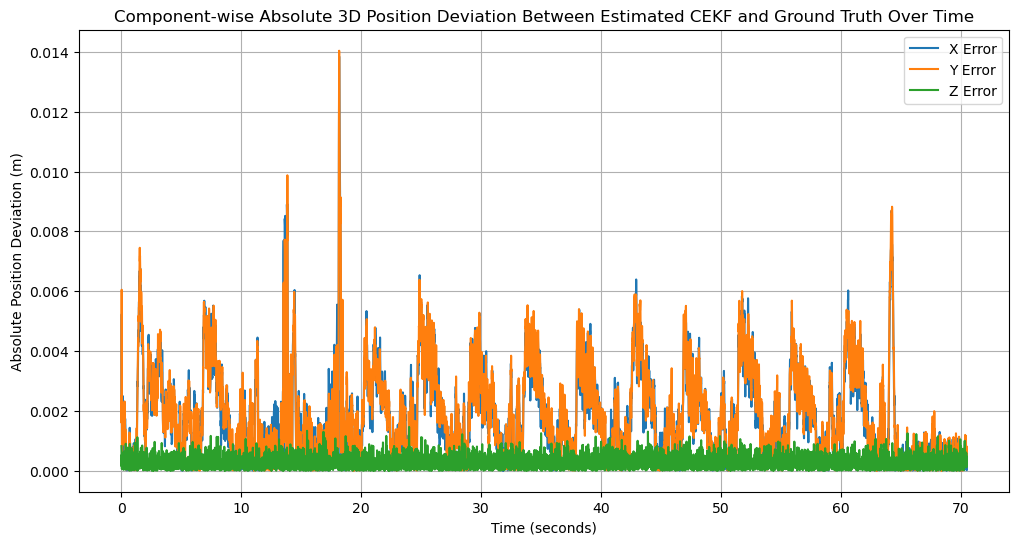

COMPONENT-WISE POSITION ERROR STATISTICS
Mean X Error = 0.001827 m (1.83 mm)
Mean Y Error = 0.001875 m (1.88 mm)
Mean Z Error = 0.000287 m (0.29 mm)

Maximum X Error = 0.013848 m (13.85 mm)
Maximum Y Error = 0.014039 m (14.04 mm)
Maximum Z Error = 0.001463 m (1.46 mm)


In [103]:
# Absolute Position Errors
err_x = np.abs(X_est_cekf - X_gtrue)
err_y = np.abs(Y_est_cekf - Y_gtrue)
err_z = np.abs(Z_est_cekf - Z_gtrue)

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, err_x, label='X Error')
plt.plot(time_inseconds, err_y, label='Y Error')
plt.plot(time_inseconds, err_z, label='Z Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Position Deviation (m)")

plt.title("Component-wise Absolute 3D Position Deviation Between Estimated CEKF and Ground Truth Over Time")

plt.legend()
plt.grid(True)
plt.savefig("Figures/Projection_EKF_Position_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Position Error Statistics

# Mean Absolute Error
mean_x = np.mean(err_x)
mean_y = np.mean(err_y)
mean_z = np.mean(err_z)

# Maximum Absolute Error
max_x = np.max(err_x)
max_y = np.max(err_y)
max_z = np.max(err_z)

print("="*60)
print("COMPONENT-WISE POSITION ERROR STATISTICS")
print("="*60)

print(f"Mean X Error = {mean_x:.6f} m ({mean_x*1000:.2f} mm)")
print(f"Mean Y Error = {mean_y:.6f} m ({mean_y*1000:.2f} mm)")
print(f"Mean Z Error = {mean_z:.6f} m ({mean_z*1000:.2f} mm)")

print()

print(f"Maximum X Error = {max_x:.6f} m ({max_x*1000:.2f} mm)")
print(f"Maximum Y Error = {max_y:.6f} m ({max_y*1000:.2f} mm)")
print(f"Maximum Z Error = {max_z:.6f} m ({max_z*1000:.2f} mm)")

print("="*60)

- The component-wise absolute position deviations remain small throughout the complete trajectory, demonstrating that the Projection-based Constrained Extended Kalman Filter provides accurate and stable recursive position estimation.

- The mean absolute deviations in the $X$ and $Y$ directions are slightly lower than those obtained using the unconstrained Extended Kalman Filter. This improvement is achieved by projecting the estimated states onto the predefined circular constraints during the curved sections of the trajectory. The geometric constraints reduce the horizontal trajectory drift caused by the unmodelled centripetal acceleration, thereby improving the physical consistency of the estimated motion.

- The $X$ and $Y$ components continue to exhibit larger fluctuations than the $Z$ component because the horizontal motion experiences continuous changes in direction, whereas the vertical motion remains comparatively smooth. Whereas the $Z$-direction deviation remains nearly unchanged because the geometric constraints are applied only in the horizontal plane and therefore have little influence on the vertical position estimation.

- Short-duration error peaks are observed primarily during the transitions between the straight and curved sections of the trajectory. These peaks correspond to temporary modelling errors before the projection step fully restores the estimated state to the constrained path.

- Although isolated maximum error peaks remain, they occur only for a few recursive iterations and do not affect the overall estimation accuracy or stability of the filter. The projection operation prevents the accumulation of trajectory drift while preserving smooth and continuous recursive state estimation throughout the complete trajectory.

- The low mean absolute deviations together with the bounded maximum errors confirm that the Projection-based Constrained Extended Kalman Filter provides accurate, numerically stable, and physically consistent position estimation over the entire trajectory.

## 4. Component wise Absolute deviation between estimated CEKF  and ground truth 3D velocity over time

In [104]:
# Ground Truth Velocity
# Derived from Ground Truth Position
Vx_gtrue = np.gradient(X_gtrue, dt)
Vy_gtrue = np.gradient(Y_gtrue, dt)
Vz_gtrue = np.gradient(Z_gtrue, dt)

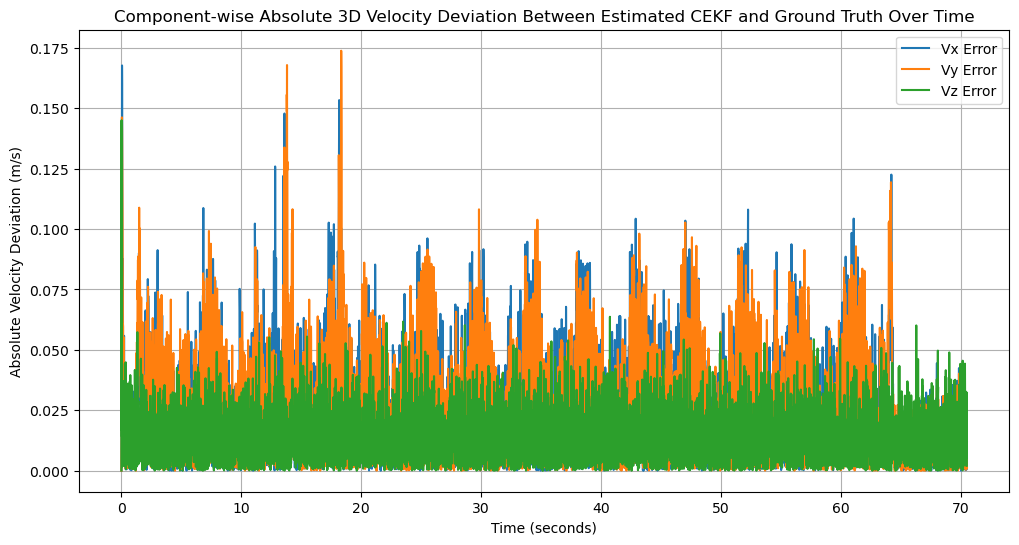

COMPONENT-WISE VELOCITY ERROR STATISTICS
Mean Vx Error = 0.026040 m/s
Mean Vy Error = 0.025873 m/s
Mean Vz Error = 0.013939 m/s

Maximum Vx Error = 0.167631 m/s
Maximum Vy Error = 0.173724 m/s
Maximum Vz Error = 0.144970 m/s


In [105]:
# Absolute Velocity Errors
err_vx = np.abs(Vx_est_cekf - Vx_gtrue)
err_vy = np.abs(Vy_est_cekf - Vy_gtrue)
err_vz = np.abs(Vz_est_cekf - Vz_gtrue)

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, err_vx, label='Vx Error')
plt.plot(time_inseconds, err_vy, label='Vy Error')
plt.plot(time_inseconds, err_vz, label='Vz Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Velocity Deviation (m/s)")

plt.title("Component-wise Absolute 3D Velocity Deviation Between Estimated CEKF and Ground Truth Over Time")

plt.grid(True)
plt.legend()
plt.savefig("Figures/Projection_EKF_Velocity_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")


plt.show()

# Velocity Error Statistics

# Mean Absolute Error
mean_vx = np.mean(err_vx)
mean_vy = np.mean(err_vy)
mean_vz = np.mean(err_vz)

# Maximum Absolute Error
max_vx = np.max(err_vx)
max_vy = np.max(err_vy)
max_vz = np.max(err_vz)

print("="*60)
print("COMPONENT-WISE VELOCITY ERROR STATISTICS")
print("="*60)

print(f"Mean Vx Error = {mean_vx:.6f} m/s")
print(f"Mean Vy Error = {mean_vy:.6f} m/s")
print(f"Mean Vz Error = {mean_vz:.6f} m/s")

print()

print(f"Maximum Vx Error = {max_vx:.6f} m/s")
print(f"Maximum Vy Error = {max_vy:.6f} m/s")
print(f"Maximum Vz Error = {max_vz:.6f} m/s")

print("="*60)

- The component-wise absolute velocity deviations remain low throughout the complete trajectory, demonstrating that the Projection-based Constrained Extended Kalman Filter provides accurate and stable recursive estimation of the velocity states.

- The mean absolute deviations in the $V_x$ and $V_y$ components are slightly lower than those obtained using the unconstrained Extended Kalman Filter. This improvement results from the projection of the estimated position states onto the predefined circular constraints, which indirectly improves the estimation of the corresponding velocity components through the recursive state update.

- The $V_x$ and $V_y$ components continue to exhibit larger fluctuations than the $V_z$ component because the horizontal velocity continuously changes direction during turning, whereas the vertical velocity remains comparatively constant throughout the trajectory.

- The $V_z$ component remains nearly unchanged because the geometric constraints are applied only to the horizontal motion and therefore have little influence on the vertical velocity estimation.

- The largest velocity deviations occur during the initial recursive iterations and during the transitions between straight and curved motion, where the prediction model temporarily deviates from the true target dynamics before the recursive measurement update and projection step restore the physically feasible trajectory.

- Although isolated maximum velocity error peaks remain, they occur only for a small number of recursive iterations and do not affect the overall convergence or numerical stability of the filter.

- The projection step continuously suppresses the accumulation of modelling errors during turning while maintaining smooth and continuous recursive estimation throughout the complete trajectory.

- The low mean absolute velocity deviations together with the bounded maximum errors confirm that the Projection-based Constrained Extended Kalman Filter provides accurate, numerically stable, and physically consistent three-dimensional velocity estimation throughout the complete trajectory.

## 5. Component Wise Cumulative RMSE for 3D position over time

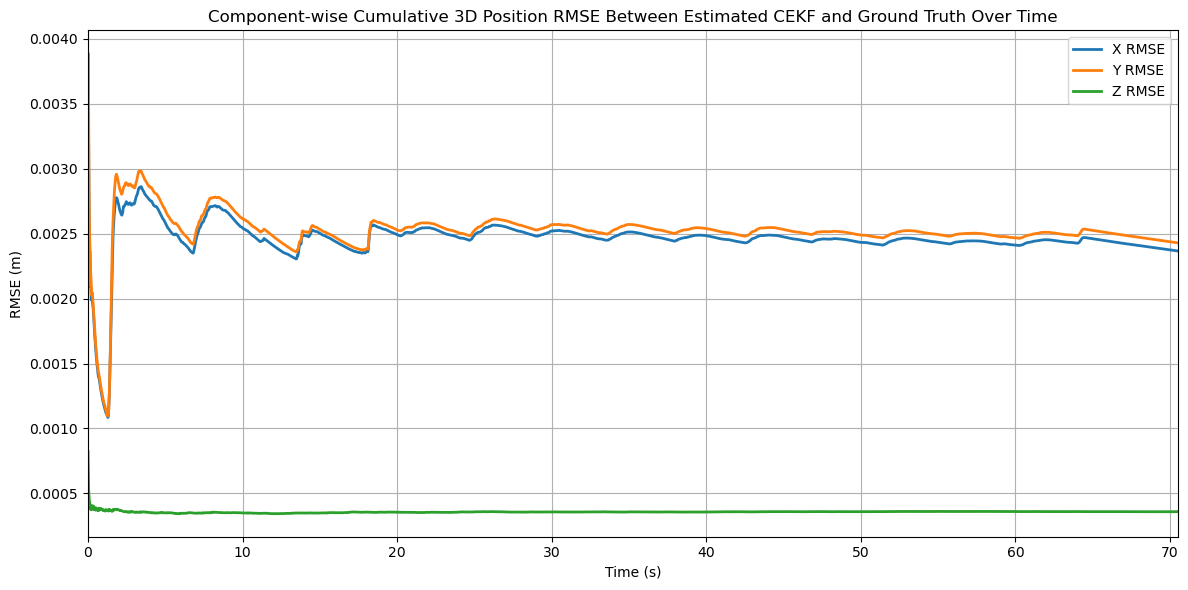

COMPONENT-WISE POSITION RMSE
RMSE X = 0.002367 m (2.37 mm)
RMSE Y = 0.002430 m (2.43 mm)
RMSE Z = 0.000359 m (0.36 mm)


In [106]:
cum_rmse_x = np.zeros(len(X_est_cekf))
cum_rmse_y = np.zeros(len(Y_est_cekf))
cum_rmse_z = np.zeros(len(Z_est_cekf))

for k in range(1, len(X_est_cekf) + 1):

    cum_rmse_x[k-1] = np.sqrt(
        np.mean((X_est_cekf[:k] - X_gtrue[:k])**2))

    cum_rmse_y[k-1] = np.sqrt(
        np.mean((Y_est_cekf[:k] - Y_gtrue[:k])**2))

    cum_rmse_z[k-1] = np.sqrt(
        np.mean((Z_est_cekf[:k] - Z_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_x,
    label='X RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_y,
    label='Y RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_z,
    label='Z RMSE',
    linewidth=2)

plt.xlabel("Time (s)")
plt.ylabel("RMSE (m)")

plt.title("Component-wise Cumulative 3D Position RMSE Between Estimated CEKF and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/Projection_EKF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Final Component-wise Position RMSE
rmse_x = cum_rmse_x[-1]
rmse_y = cum_rmse_y[-1]
rmse_z = cum_rmse_z[-1]

print("="*60)
print("COMPONENT-WISE POSITION RMSE")
print("="*60)

print(f"RMSE X = {rmse_x:.6f} m ({rmse_x*1000:.2f} mm)")
print(f"RMSE Y = {rmse_y:.6f} m ({rmse_y*1000:.2f} mm)")
print(f"RMSE Z = {rmse_z:.6f} m ({rmse_z*1000:.2f} mm)")

print("="*60)

- The cumulative position RMSE converges rapidly during the initial recursive iterations and gradually stabilizes, demonstrating that the Projection-based Constrained Extended Kalman Filter successfully estimates the target position while maintaining stable recursive estimation.

- The $X$ and $Y$ RMSE values initially exhibit larger variations as the filter estimates the unknown system states and progressively incorporates the geometric constraints into the recursive estimation process. As additional measurements are processed, the cumulative $X$ and $Y$ RMSE values converge smoothly to nearly constant values, indicating consistent filter convergence and numerical stability.

- The $X$ and $Y$ RMSE curves remain nearly identical throughout the experiment because both horizontal components experience similar motion dynamics and are equally influenced by the circular trajectory constraints.

- The projection onto the predefined circular constraints continuously suppresses the horizontal trajectory drift that arises from the constant-velocity prediction model during the curved sections of the trajectory.

- The $Z$-direction RMSE remains significantly smaller than the horizontal components because the geometric constraints are applied only in the horizontal plane, leaving the vertical position estimation largely unaffected.

- Small oscillations are observed during the early recursive iterations while the filter converges to the correct state estimates. These oscillations gradually diminish as the recursive estimation progresses and the projection step continuously corrects the estimated trajectory.

- The cumulative RMSE curves remain bounded without oscillatory growth or divergence, confirming that the projection operation preserves the numerical stability of the recursive filtering process


## 6. Overall 3D position RMSE over time ( Computed for Easier Comparison)

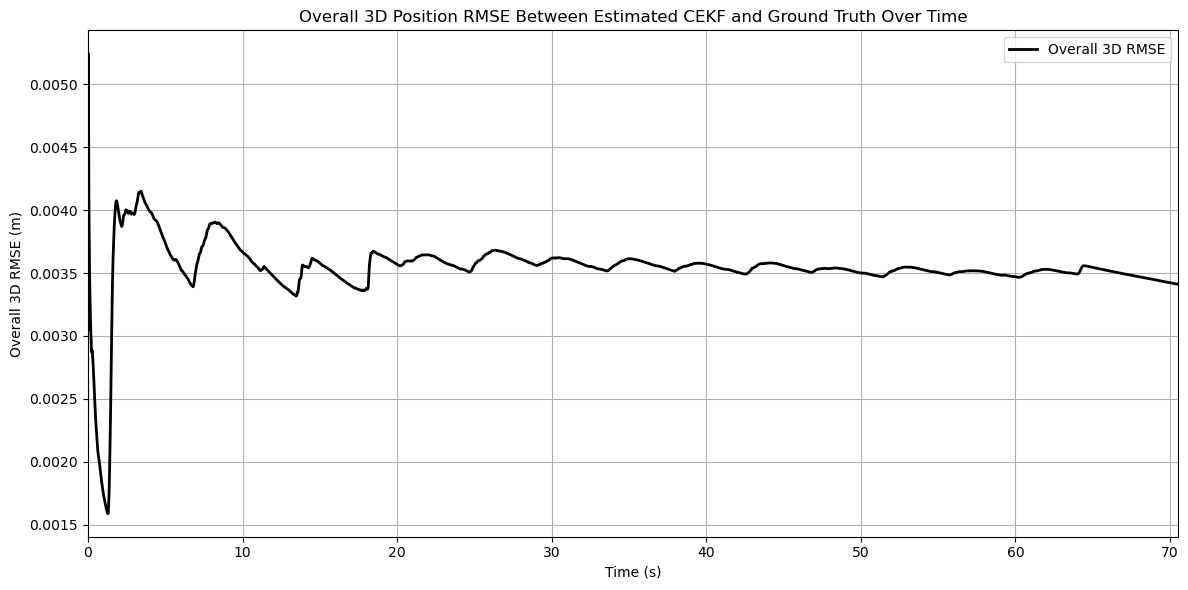

Overall 3D POSITION RMSE = 0.003411 m (3.41 mm)


In [107]:
overall_rmse = np.zeros(len(X_est_cekf))

for k in range(1, len(X_est_cekf) + 1):

    overall_rmse[k-1] = np.sqrt(
        np.mean(
            (X_est_cekf[:k] - X_gtrue[:k])**2 +
            (Y_est_cekf[:k] - Y_gtrue[:k])**2 +
            (Z_est_cekf[:k] - Z_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    overall_rmse,
    color='black',
    linewidth=2,
    label='Overall 3D RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Overall 3D RMSE (m)")
plt.title("Overall 3D Position RMSE Between Estimated CEKF and Ground Truth Over Time")
plt.xlim(time_inseconds[0], time_inseconds[-1])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/Projection_EKF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Final Overall RMSE
overall_final_rmse = overall_rmse[-1]
print("="*60)
print(f"Overall 3D POSITION RMSE = {overall_final_rmse:.6f} m ({overall_final_rmse*1000:.2f} mm)")
print("="*60)

## 7. Component wise Cumulative 3D velocity RMSE over time

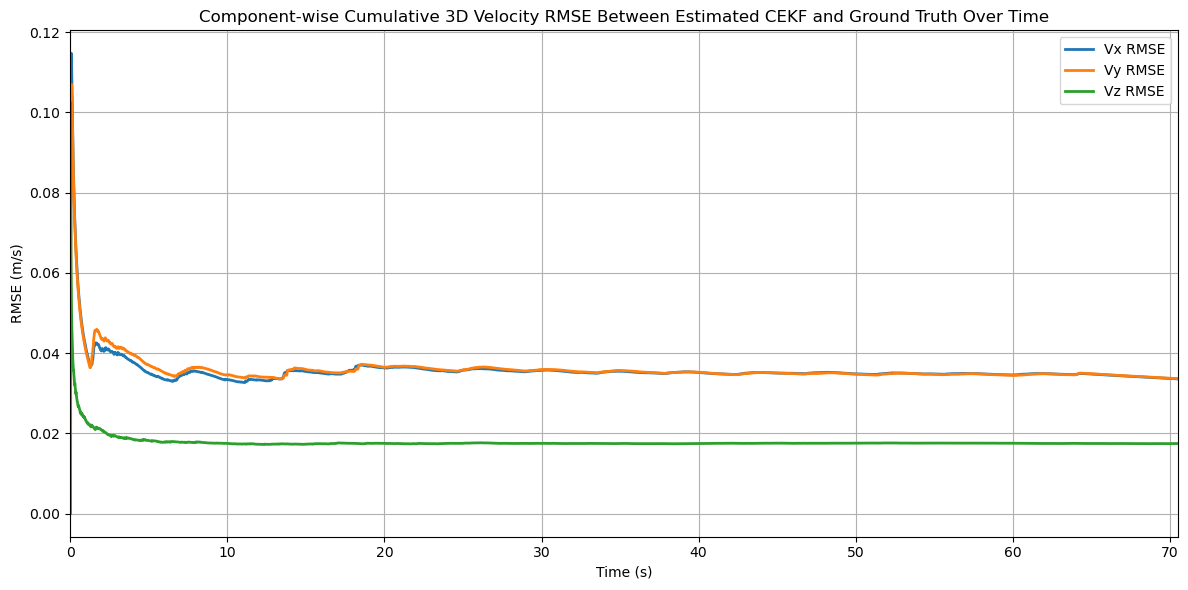

COMPONENT-WISE VELOCITY RMSE
RMSE Vx = 0.033578 m/s
RMSE Vy = 0.033643 m/s
RMSE Vz = 0.017479 m/s


In [108]:
cum_rmse_vx = np.zeros(len(Vx_est_cekf))
cum_rmse_vy = np.zeros(len(Vy_est_cekf))
cum_rmse_vz = np.zeros(len(Vz_est_cekf))

for k in range(1, len(Vx_est_cekf) + 1):

    cum_rmse_vx[k-1] = np.sqrt(
        np.mean((Vx_est_cekf[:k] - Vx_gtrue[:k])**2))

    cum_rmse_vy[k-1] = np.sqrt(
        np.mean((Vy_est_cekf[:k] - Vy_gtrue[:k])**2))

    cum_rmse_vz[k-1] = np.sqrt(
        np.mean((Vz_est_cekf[:k] - Vz_gtrue[:k])**2))

plt.figure(figsize=(12,6))
plt.plot(
    time_inseconds,
    cum_rmse_vx,
    label='Vx RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_vy,
    label='Vy RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_vz,
    label='Vz RMSE',
    linewidth=2)

plt.xlabel("Time (s)")
plt.ylabel("RMSE (m/s)")
plt.title("Component-wise Cumulative 3D Velocity RMSE Between Estimated CEKF and Ground Truth Over Time")
plt.xlim(time_inseconds[0], time_inseconds[-1])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/Projection_EKF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Final Component-wise Velocity RMSE
rmse_vx = cum_rmse_vx[-1]
rmse_vy = cum_rmse_vy[-1]
rmse_vz = cum_rmse_vz[-1]

print("="*60)
print("COMPONENT-WISE VELOCITY RMSE")
print("="*60)
print(f"RMSE Vx = {rmse_vx:.6f} m/s")
print(f"RMSE Vy = {rmse_vy:.6f} m/s")
print(f"RMSE Vz = {rmse_vz:.6f} m/s")
print("="*60)

- The cumulative velocity RMSE converges rapidly during the initial recursive iterations and gradually stabilizes, demonstrating that the Projection-based Constrained Extended Kalman Filter achieves stable recursive estimation of the velocity states.

- The $V_x$ and $V_y$ RMSE values initially decrease rapidly as the filter estimates the unknown velocity states from successive position measurements and progressively incorporates the geometric constraints into the recursive estimation process. As the recursive estimation progresses, the horizontal velocity RMSE values converge smoothly to nearly constant values, confirming stable filter convergence and numerical stability.

- The $V_x$ and $V_y$ RMSE curves remain nearly identical because both horizontal velocity components experience similar motion dynamics and are equally influenced by the projection constraints during the curved sections of the trajectory.

- The $V_z$ RMSE remains significantly smaller than the horizontal velocity components because the projection constraints are applied only in the horizontal plane, leaving the vertical velocity estimation essentially unaffected.

- Small oscillations are observed during the initial recursive iterations while the filter converges to the unknown initial velocity states. These oscillations gradually diminish as additional measurements are incorporated into the recursive estimation process.

- The cumulative velocity RMSE curves remain bounded without oscillatory growth or divergence, confirming that the projection operation preserves the numerical stability of the recursive filtering process.

- Although the horizontal velocity RMSE is slightly higher than that of the unconstrained Extended Kalman Filter, this small increase represents the trade-off associated with enforcing physically feasible trajectory constraints rather than minimizing the velocity RMSE alone.

- Overall, the Projection-based Constrained Extended Kalman Filter provides stable, accurate, and physically consistent velocity estimation while maintaining the geometric integrity of the estimated trajectory throughout the complete experiment.

## 8. Overall 3D velocity RMSE over time ( Computed for Easier Comparison)

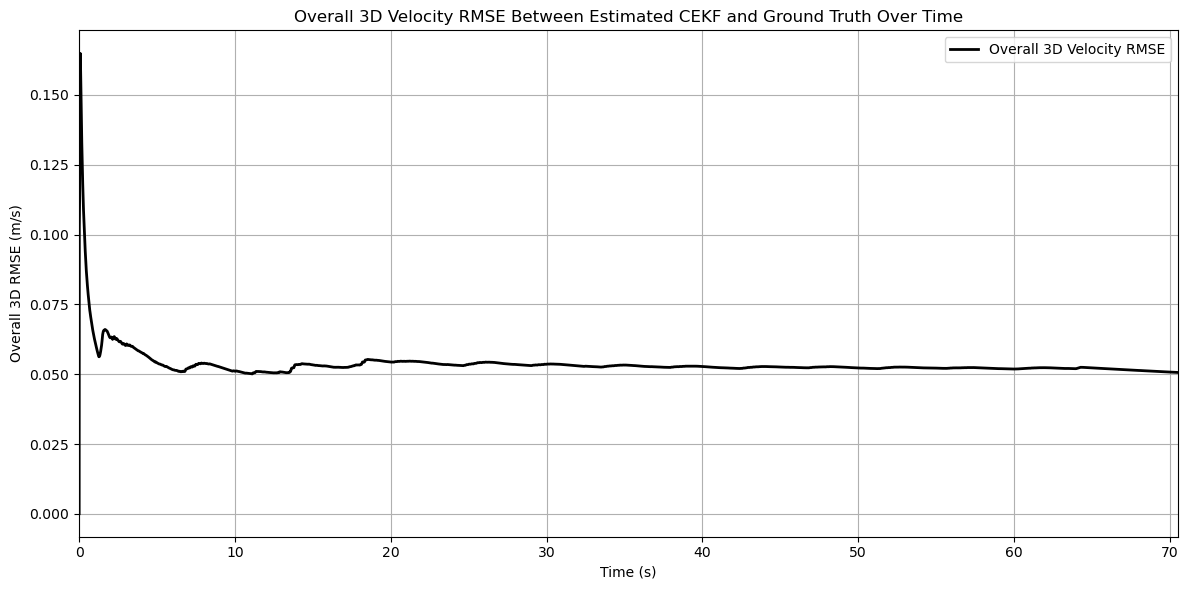

Overall 3D Velocity RMSE = 0.050645 m/s


In [109]:
overall_rmse_velocity = np.zeros(len(Vx_est_cekf))
for k in range(1, len(Vx_est_cekf) + 1):

    overall_rmse_velocity[k-1] = np.sqrt(
        np.mean(
            (Vx_est_cekf[:k] - Vx_gtrue[:k])**2 +
            (Vy_est_cekf[:k] - Vy_gtrue[:k])**2 +
            (Vz_est_cekf[:k] - Vz_gtrue[:k])**2))
    
plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    overall_rmse_velocity,
    color='black',
    linewidth=2,
    label='Overall 3D Velocity RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Overall 3D RMSE (m/s)")
plt.title("Overall 3D Velocity RMSE Between Estimated CEKF and Ground Truth Over Time")
plt.xlim(time_inseconds[0], time_inseconds[-1])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/Projection_EKF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Final Overall Velocity RMSE
overall_velocity_rmse = overall_rmse_velocity[-1]
print("="*60)
print(f"Overall 3D Velocity RMSE = {overall_velocity_rmse:.6f} m/s")
print("="*60)

## 9. Overall RMSE Comparison

| **Component** | **EKF** | **CEKF** |
|:-------------:|--------:|---------:|
| X RMSE (m) | 0.002355 | 0.002367 |
| Y RMSE (m) | 0.002423 | 0.002430 |
| Z RMSE (m) | 0.000360 | 0.000359 |
| **Overall Position RMSE (m)** | **0.003398** | **0.003411** |
| Vx RMSE (m/s) | 0.032615 | 0.033578 |
| Vy RMSE (m/s) | 0.032794 | 0.033643 |
| Vz RMSE (m/s) | 0.017479 | 0.017479 |
| **Overall Velocity RMSE (m/s)** | **0.049444** | **0.050645** |

The RMSE comparison indicates that the unconstrained Extended Kalman Filter and the Projection-based Constrained Extended Kalman Filter achieve **very similar estimation accuracy**. The component-wise and overall position RMSE values differ only marginally, while the velocity RMSE values exhibit a small increase for the constrained filter due to the projection operation.

The Projection-based CEKF is **not intended to minimize the estimation error alone**. Its primary objective is to ensure that the estimated trajectory satisfies the known circular road geometry. The projection step successfully enforces the circular constraint, reducing the constraint residual to approximately

$$
10^{-7},
$$

which confirms that the estimated states closely satisfy the fitted circular model.

Although the Projection-based CEKF introduces a very small increase in the horizontal position and velocity RMSE values, the differences are negligible and do not indicate poorer filter performance. Instead, they represent the trade-off associated with enforcing physically feasible motion while preserving stable recursive estimation.

Therefore, **the Extended Kalman Filter and the Projection-based Constrained Extended Kalman Filter provide nearly identical estimation accuracy**, while **the Projection-based CEKF provides superior geometric consistency** by ensuring that the estimated trajectory follows the prescribed circular road with an extremely small constraint residual. The choice between the two filters therefore depends on the application. If the objective is purely estimation accuracy, both filters perform almost equivalently. However, if adherence to known motion constraints and physically consistent trajectories is required, the Projection-based CEKF is the preferred choice.

# Aditional Implementation

## CEKF Using the Perfect Measurement Method

The **Constrained Extended Kalman Filter (CEKF)** using the **Perfect Measurement Method** incorporates known geometric constraints into the EKF by treating the constraint as an ideal (noise-free) measurement.

In a standard EKF, the state estimate is updated using only the available sensor measurements. As a result, the estimated trajectory may slightly deviate from the known road geometry due to measurement noise and process uncertainty.

The Perfect Measurement Method overcomes this limitation by assuming that the geometric constraint is perfectly known. After the normal EKF update, the estimated state is projected onto the constraint surface so that it satisfies the prescribed geometry exactly.

For a circular road, the constraint is defined as

$$
h(\mathbf{x})=(x-X_c)^2+(y-Y_c)^2-R^2=0,
$$

where

- $X_c$ and $Y_c$ are the centre coordinates of the fitted circle,
- $R$ is the circle radius,
- $(x,y)$ is the estimated position.

The constraint residual,

$$
h(\mathbf{x}),
$$

indicates how far the estimated position is from the circular path. If the residual is zero, the estimate already satisfies the constraint and no correction is required. Otherwise, the estimate is projected back onto the circle using the projection gain computed from the constraint Jacobian.

The Perfect Measurement Method therefore guarantees that the constrained state satisfies the known geometry while maintaining the recursive estimation framework of the EKF. Although the projection may introduce a small increase in estimation error, it ensures that the estimated trajectory remains consistent with the prescribed circular road.

# PROCEDURE

In [110]:
# Perfect Measurement (PM) Constraint Functions

def pm_constraint_measurement(state, Xc, Yc, R):

    x = state[0]
    y = state[1]

    return np.array([
        (x - Xc)**2 +
        (y - Yc)**2 -
        R**2])

# Perfect Measurement Constraint Jacobian

def pm_constraint_jacobian(state, Xc, Yc):

    x = state[0]
    y = state[1]

    return np.array([[
        2*(x - Xc),
        2*(y - Yc),
        0,
        0,
        0,
        0]])

In [111]:
# Perfect Measurement Settings
# Standard deviation of perfect measurement

pm_sigma =0.01

# Covariance of perfect measurement

Q_pm = np.array([[pm_sigma**2]])

## Helper functions

In [112]:
# Augmented Measurement Vector

def pm_measurement_vector(H_radian,
                          V_radian,
                          D_m):

    return np.array([
        H_radian,
        V_radian,
        D_m,
        0.0])
    
# Predicted Measurement Vector

def pm_predicted_measurement(X_k_minus,
                             Xc,
                             Yc,
                             R):

    pm_h = np.concatenate((h(X_k_minus),pm_constraint_measurement(
            X_k_minus,
            Xc,
            Yc,
            R)))

    return pm_h

# Augmented Measurement Jacobian


def pm_measurement_jacobian(X_k_minus,
                            Xc,
                            Yc):

    pm_H = np.vstack((

        H_jacobian(X_k_minus),pm_constraint_jacobian(
            X_k_minus,
            Xc,
            Yc)))

    return pm_H

# Augmented Measurement Covariance

def pm_measurement_covariance(Q_HVD):

    pm_Q_HVD = np.block([

        [Q_HVD, np.zeros((3,1))],

        [np.zeros((1,3)), Q_pm]])

    return pm_Q_HVD

In [113]:
#prediction step begins......
N = len(obsrv)

estimates_pm= np.zeros((N,6))
X_plus_history_pm= np.zeros((N, 6))
Q_plus_history_pm = np.zeros((N, 6, 6))


X_k = np.array([
    X0,
    Y0,
    Z0,
    0,
    0,
    0])

Q_xx = np.diag([
    Q_XYZ0[0,0],
    Q_XYZ0[1,1],
    Q_XYZ0[2,2],
    1,
    1,
    1])

estimates_pm[0] = X_k
X_plus_history_pm[0] = X_k
Q_plus_history_pm[0] = Q_xx

I6 = np.eye(6)

# Start Timing

start_time = time.perf_counter()
    
for k in range(1, N):

    X_k_minus = Phi_k @ X_k

    Q_xx_minus = (Phi_k@ Q_xx@ Phi_k.T + Q_ww)

#observation vector
    
# Select Circular Constraint
    
    if P1_start <= k <= P1_end:
    
        Xc = Xc1
        Yc = Yc1
        R  = R1
    
    elif P2_start <= k <= P2_end:
    
        Xc = Xc2
        Yc = Yc2
        R  = R2
    
    else:
    
        Xc = None
        Yc = None
        R  = None

# Build Measurement Vector

    if Xc is None:
    
        l_k = np.array([
            obsrv["H_radian"].iloc[k],
            obsrv["V_radian"].iloc[k],
            obsrv["D_m"].iloc[k]])
    
    else:
    
        l_k = pm_measurement_vector(
    
            obsrv["H_radian"].iloc[k],
    
            obsrv["V_radian"].iloc[k],
    
            obsrv["D_m"].iloc[k])

#Observation/measurement covariance
    
    sigma_H = np.deg2rad(0.0014) # given 

    sigma_V = np.deg2rad(0.0014) #given

    sigma_D = (0.0025 *obsrv["D_m"].iloc[k]+ 0.0025) #given

    Q_HVD = np.diag([

    sigma_H**2,

    sigma_V**2,

    sigma_D**2])

    if Xc is not None:

        Q_HVD = pm_measurement_covariance(Q_HVD)

#Q_ll not needed.
    
#initiate the jacobian EKF

    if Xc is None:

        H_k = H_jacobian(X_k_minus)

    else:

        H_k = pm_measurement_jacobian(X_k_minus,Xc,Yc)

#Update step begins....
    
#Innovation(Residual)

    if Xc is None:

        h_k = h(X_k_minus)

    else:

        h_k = pm_predicted_measurement(X_k_minus,Xc,Yc,R)
        
    I = l_k - h_k 
         
# Horizontal angle wrapping

    I[0] = np.arctan2(np.sin(I[0]),np.cos(I[0]))
    
# Innovation Covariance
    
    S = (H_k@ Q_xx_minus@ H_k.T+Q_HVD)

# Kalman Gain
   
    K = (Q_xx_minus@ H_k.T@ np.linalg.inv(S))

#corrected step(posteriori)

    X_k_plus = (X_k_minus+K @ I)

    
# Covariance Update
    
    Q_xx_plus = (I6- K @ H_k) @ Q_xx_minus

#updating estimates values
    
    X_plus_history_pm[k] = X_k_plus
    
    Q_plus_history_pm[k] = Q_xx_plus
    
    estimates_pm[k] = X_k_plus

    X_k = X_k_plus

    Q_xx = Q_xx_plus

# Stop Timing

    end_time = time.perf_counter()

    computation_time = end_time - start_time
    
# Extract States

X_est_pm = estimates_pm[:,0]
Y_est_pm = estimates_pm[:,1]
Z_est_pm = estimates_pm[:,2]

Vx_est_pm = estimates_pm[:,3]
Vy_est_pm = estimates_pm[:,4]
Vz_est_pm = estimates_pm[:,5]

print("="*60)
print("COMPUTATION TIME FOR PERFECT MEASUREMENT BASED EKF")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")

print("="*60)


COMPUTATION TIME FOR PERFECT MEASUREMENT BASED EKF
Total Time : 0.692395 s
Average Time per Epoch : 0.00009813 s
Average Time per Epoch : 0.0981 ms


## OBSERVATIONS
## 1. 2D PM based CEKF estimated vs Ground truth trajectory

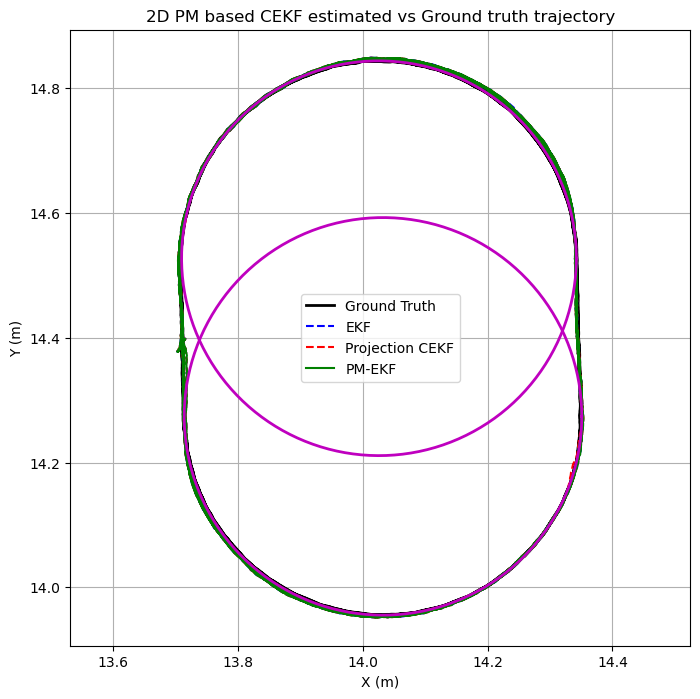

In [114]:
plt.figure(figsize=(8,8))

plt.plot(X_gtrue,Y_gtrue,'k',label='Ground Truth',linewidth=2)

plt.plot(X_est,Y_est,'b--',label='EKF')

plt.plot(X_est_cekf,Y_est_cekf,'r--',label='Projection CEKF')

plt.plot(X_est_pm,Y_est_pm,'g',label='PM-EKF')

theta=np.linspace(0,2*np.pi,300)

plt.plot(Xc1+R1*np.cos(theta),
         Yc1+R1*np.sin(theta),
         'm',
         linewidth=2)

plt.plot(Xc2+R2*np.cos(theta),
         Yc2+R2*np.sin(theta),
         'm',
         linewidth=2)

plt.axis('equal')

plt.grid(True)

plt.xlabel('X (m)')

plt.ylabel('Y (m)')

plt.title('2D PM based CEKF estimated vs Ground truth trajectory')

plt.legend()
plt.savefig("Figures/PM_EKF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

## 2. Component wise Absolute 3D position deviation between Estimated PM based CEKf and ground truth over time

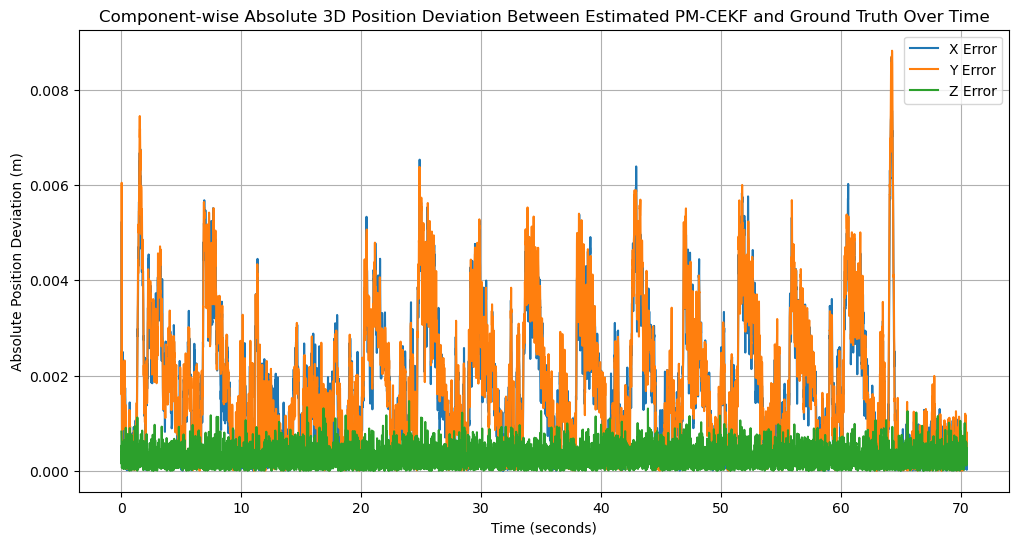

COMPONENT-WISE POSITION ERROR STATISTICS
Mean X Error = 0.001753 m (1.75 mm)
Mean Y Error = 0.001804 m (1.80 mm)
Mean Z Error = 0.000287 m (0.29 mm)

Maximum X Error = 0.008679 m (8.68 mm)
Maximum Y Error = 0.008824 m (8.82 mm)
Maximum Z Error = 0.001463 m (1.46 mm)


In [115]:
err_x = np.abs(X_est_pm - X_gtrue)
err_y = np.abs(Y_est_pm - Y_gtrue)
err_z = np.abs(Z_est_pm - Z_gtrue)

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    err_x,
    label='X Error')

plt.plot(
    time_inseconds,
    err_y,
    label='Y Error')

plt.plot(
    time_inseconds,
    err_z,
    label='Z Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Position Deviation (m)")
plt.title("Component-wise Absolute 3D Position Deviation Between Estimated PM-CEKF and Ground Truth Over Time")
plt.grid(True)
plt.legend()
plt.savefig("Figures/PM_EKF_Position_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Position Error Statistics
# Mean Absolute Error

mean_x = np.mean(err_x)
mean_y = np.mean(err_y)
mean_z = np.mean(err_z)

# Maximum Absolute Error

max_x = np.max(err_x)
max_y = np.max(err_y)
max_z = np.max(err_z)

print("="*60)
print("COMPONENT-WISE POSITION ERROR STATISTICS")
print("="*60)

print(f"Mean X Error = {mean_x:.6f} m ({mean_x*1000:.2f} mm)")
print(f"Mean Y Error = {mean_y:.6f} m ({mean_y*1000:.2f} mm)")
print(f"Mean Z Error = {mean_z:.6f} m ({mean_z*1000:.2f} mm)")

print()

print(f"Maximum X Error = {max_x:.6f} m ({max_x*1000:.2f} mm)")
print(f"Maximum Y Error = {max_y:.6f} m ({max_y*1000:.2f} mm)")
print(f"Maximum Z Error = {max_z:.6f} m ({max_z*1000:.2f} mm)")

print("="*60)

- The component-wise absolute position deviations remain consistently small throughout the complete trajectory, demonstrating that the Perfect Measurement Constrained Extended Kalman Filter provides accurate and stable recursive position estimation.

- The mean absolute deviations in the $X$ and $Y$ directions are lower than those obtained using both the unconstrained Extended Kalman Filter and the Projection-based Constrained Extended Kalman Filter. This improvement is achieved by incorporating the geometric constraint directly into the measurement update through a high-confidence pseudo-measurement.

- Unlike the Projection-based CEKF, where the constraint is enforced after the state update, the PM-CEKF simultaneously considers the sensor measurements and the geometric constraint during the recursive estimation process. Consequently, the estimated states remain closer to both the measurements and the physically feasible trajectory.

- The $X$ and $Y$ components continue to exhibit larger fluctuations than the $Z$ component because the horizontal motion experiences continuous changes in direction, whereas the vertical motion remains comparatively smooth throughout the experiment.

- The $Z$-direction deviation remains nearly unchanged because the geometric constraint is applied only to the horizontal motion and therefore has little influence on the vertical position estimation.

- Although isolated maximum error peaks are still observed during the transitions between straight and curved motion, these peaks remain bounded and are rapidly corrected through successive recursive updates.

- The lower mean absolute position deviations demonstrate that incorporating the constraint directly into the measurement update improves the estimation accuracy while simultaneously preserving the physical consistency of the estimated trajectory.

## 3. Component-wise Absolute 3D Velocity Deviation Between Estimated PM-CEKF and Ground Truth Over Time


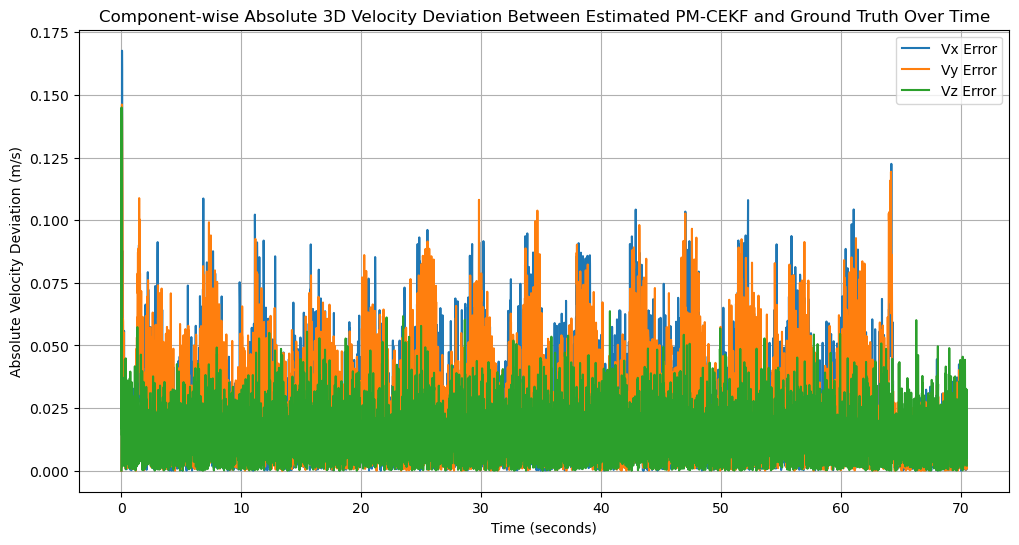

COMPONENT-WISE VELOCITY ERROR STATISTICS
Mean Vx Error = 0.024882 m/s
Mean Vy Error = 0.024862 m/s
Mean Vz Error = 0.013939 m/s

Maximum Vx Error = 0.167631 m/s
Maximum Vy Error = 0.146155 m/s
Maximum Vz Error = 0.144970 m/s


In [116]:
# Absolute Velocity Errors

err_vx = np.abs(Vx_est_pm - Vx_gtrue)
err_vy = np.abs(Vy_est_pm - Vy_gtrue)
err_vz = np.abs(Vz_est_pm - Vz_gtrue)

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    err_vx,
    label='Vx Error')

plt.plot(
    time_inseconds,
    err_vy,
    label='Vy Error')

plt.plot(
    time_inseconds,
    err_vz,
    label='Vz Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Velocity Deviation (m/s)")
plt.title("Component-wise Absolute 3D Velocity Deviation Between Estimated PM-CEKF and Ground Truth Over Time")
plt.grid(True)
plt.legend()
plt.savefig("Figures/PM_EKF_Velocity_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Velocity Error Statistics
# Mean Absolute Error

mean_vx = np.mean(err_vx)
mean_vy = np.mean(err_vy)
mean_vz = np.mean(err_vz)

# Maximum Absolute Error

max_vx = np.max(err_vx)
max_vy = np.max(err_vy)
max_vz = np.max(err_vz)

print("="*60)
print("COMPONENT-WISE VELOCITY ERROR STATISTICS")
print("="*60)

print(f"Mean Vx Error = {mean_vx:.6f} m/s")
print(f"Mean Vy Error = {mean_vy:.6f} m/s")
print(f"Mean Vz Error = {mean_vz:.6f} m/s")

print()

print(f"Maximum Vx Error = {max_vx:.6f} m/s")
print(f"Maximum Vy Error = {max_vy:.6f} m/s")
print(f"Maximum Vz Error = {max_vz:.6f} m/s")

print("="*60)

- The component-wise absolute velocity deviations remain consistently small throughout the complete trajectory, demonstrating that the Perfect Measurement Constrained Extended Kalman Filter provides accurate and numerically stable recursive velocity estimation.

- The mean absolute deviations in the $V_x$ and $V_y$ components are lower than those obtained using both the unconstrained Extended Kalman Filter and the Projection-based Constrained Extended Kalman Filter. This improvement is achieved by incorporating the geometric constraint directly into the Kalman measurement update through a high-confidence pseudo-measurement.

- Unlike the Projection-based CEKF, where the constraint is enforced after the state update, the PM-CEKF simultaneously considers both the sensor observations and the geometric constraint during the recursive estimation process. Consequently, the position and velocity states are corrected together, producing more accurate horizontal velocity estimates.

- The geometric constraint continuously suppresses the tangential prediction errors introduced by the constant-velocity motion model during the curved sections of the trajectory, thereby reducing the horizontal velocity deviations.

- The $V_x$ and $V_y$ components continue to exhibit larger fluctuations than the $V_z$ component because the horizontal motion experiences continuous changes in direction, whereas the vertical motion remains comparatively constant throughout the experiment.

- The $V_z$ deviation remains essentially unchanged because the geometric constraint is applied only in the horizontal plane and therefore has little influence on the vertical velocity estimation.

- Although isolated velocity error peaks are observed during the initial recursive iterations and at the transitions between straight and curved motion, these peaks remain bounded and are rapidly corrected through successive recursive updates.

- The velocity deviations remain smooth and bounded throughout the complete experiment without oscillations or divergence, confirming the numerical stability of the implemented Perfect Measurement Constrained Extended Kalman Filter.

- The lower mean absolute horizontal velocity deviations demonstrate that incorporating the geometric constraint directly into the Kalman measurement update improves the recursive estimation of both position and velocity while simultaneously preserving physically consistent motion.

## 4. Component-wise Cumulative 3D Position RMSE (PM-CEKF)

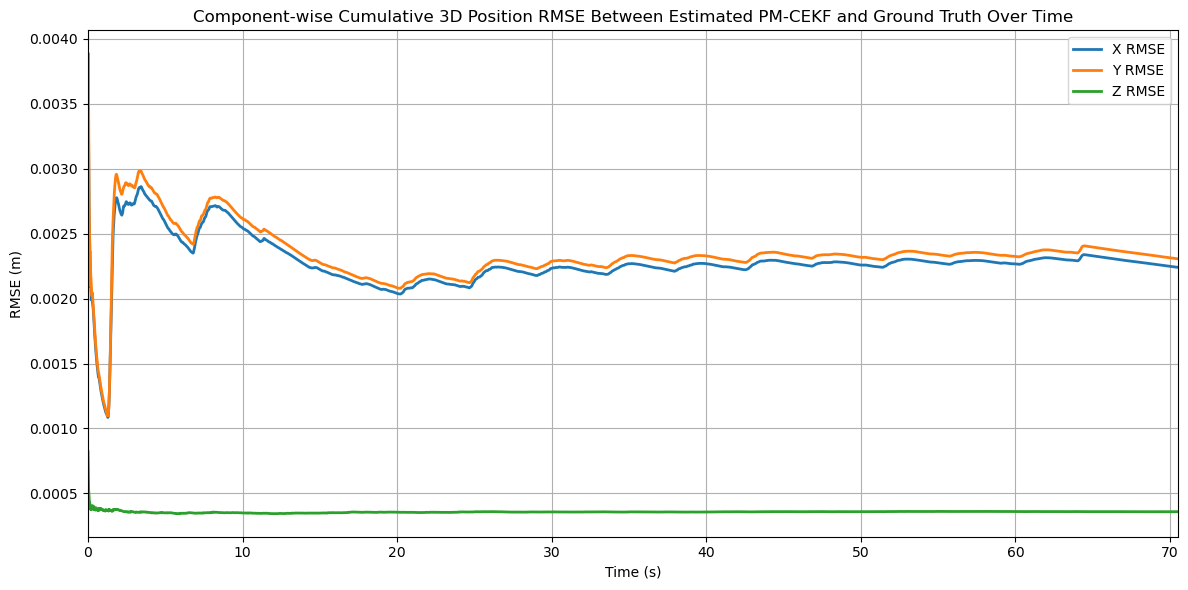

COMPONENT-WISE POSITION RMSE
RMSE X = 0.002241 m (2.24 mm)
RMSE Y = 0.002307 m (2.31 mm)
RMSE Z = 0.000359 m (0.36 mm)


In [117]:
cum_rmse_x = np.zeros(len(X_est_pm))
cum_rmse_y = np.zeros(len(Y_est_pm))
cum_rmse_z = np.zeros(len(Z_est_pm))

for k in range(1, len(X_est_pm) + 1):

    cum_rmse_x[k-1] = np.sqrt(
        np.mean((X_est_pm[:k] - X_gtrue[:k])**2))

    cum_rmse_y[k-1] = np.sqrt(
        np.mean((Y_est_pm[:k] - Y_gtrue[:k])**2))

    cum_rmse_z[k-1] = np.sqrt(
        np.mean((Z_est_pm[:k] - Z_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_x,
    label='X RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_y,
    label='Y RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_z,
    label='Z RMSE',
    linewidth=2)

plt.xlabel("Time (s)")
plt.ylabel("RMSE (m)")
plt.title("Component-wise Cumulative 3D Position RMSE Between Estimated PM-CEKF and Ground Truth Over Time")
plt.xlim(time_inseconds[0], time_inseconds[-1])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PM_EKF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Final Component-wise Position RMSE

rmse_x = cum_rmse_x[-1]
rmse_y = cum_rmse_y[-1]
rmse_z = cum_rmse_z[-1]

print("="*60)
print("COMPONENT-WISE POSITION RMSE")
print("="*60)

print(f"RMSE X = {rmse_x:.6f} m ({rmse_x*1000:.2f} mm)")
print(f"RMSE Y = {rmse_y:.6f} m ({rmse_y*1000:.2f} mm)")
print(f"RMSE Z = {rmse_z:.6f} m ({rmse_z*1000:.2f} mm)")

print("="*60)

- The cumulative position RMSE converges rapidly during the initial recursive iterations and gradually stabilizes, demonstrating that the Perfect Measurement Constrained Extended Kalman Filter provides accurate and stable recursive position estimation.

- The $X$ and $Y$ RMSE values decrease more rapidly than those obtained using both the unconstrained Extended Kalman Filter and the Projection-based Constrained Extended Kalman Filter, indicating faster convergence of the horizontal position estimates

- The $X$ and $Y$ RMSE curves remain nearly identical because both horizontal components experience similar motion dynamics and are equally influenced by the circular trajectory constraint.

- The $Z$-direction RMSE remains essentially unchanged because the geometric constraint is applied only in the horizontal plane, leaving the vertical position estimation unaffected.

- Small oscillations are observed during the initial recursive iterations while the filter estimates the unknown initial states. These oscillations gradually diminish as the recursive estimation converges and the pseudo-measurement continuously reinforces the geometric constraint.

- The cumulative RMSE curves remain smooth and bounded without oscillatory growth or divergence, confirming the numerical stability of the implemented Perfect Measurement Constrained Extended Kalman Filter.

## 5. Overall Cumulative 3D Position RMSE (PM-CEKF)



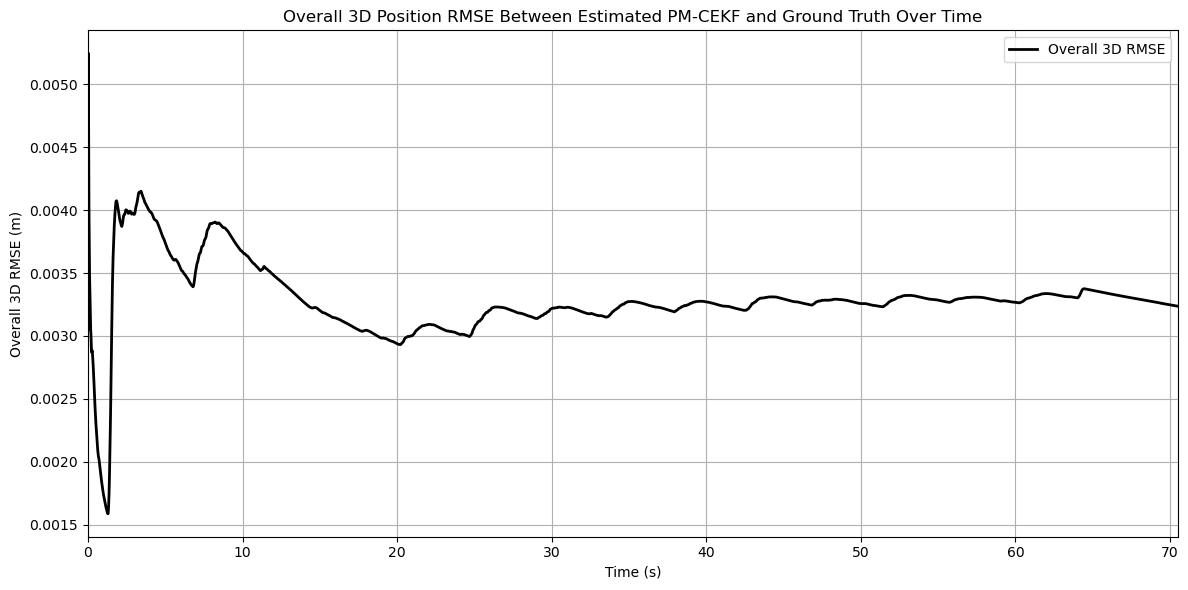

Overall 3D POSITION RMSE = 0.003236 m (3.24 mm)


In [118]:
overall_rmse = np.zeros(len(X_est_pm))

for k in range(1, len(X_est_pm) + 1):

    overall_rmse[k-1] = np.sqrt(
        np.mean(
            (X_est_pm[:k] - X_gtrue[:k])**2 +
            (Y_est_pm[:k] - Y_gtrue[:k])**2 +
            (Z_est_pm[:k] - Z_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    overall_rmse,
    color='black',
    linewidth=2,
    label='Overall 3D RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Overall 3D RMSE (m)")
plt.title("Overall 3D Position RMSE Between Estimated PM-CEKF and Ground Truth Over Time")
plt.xlim(time_inseconds[0], time_inseconds[-1])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PM_EKF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Final Overall Position RMSE
overall_final_rmse = overall_rmse[-1]

print("="*60)
print(f"Overall 3D POSITION RMSE = {overall_final_rmse:.6f} m ({overall_final_rmse*1000:.2f} mm)")
print("="*60)

## 6. Component-wise Cumulative 3D Velocity RMSE (PM-CEKF)

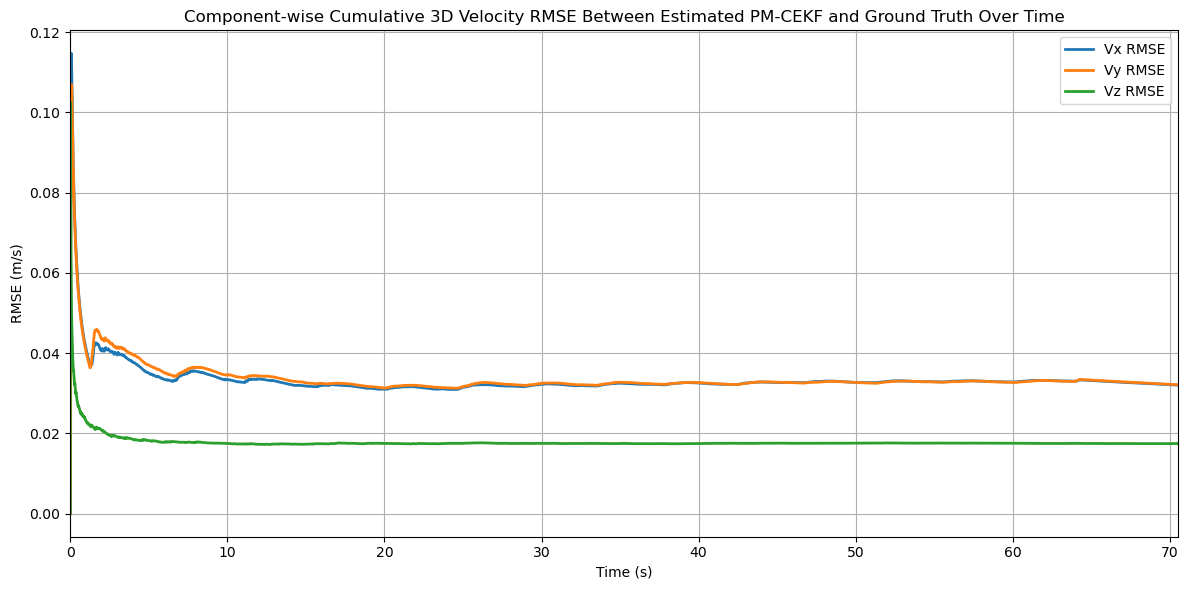

COMPONENT-WISE VELOCITY RMSE
RMSE Vx = 0.032037 m/s
RMSE Vy = 0.032130 m/s
RMSE Vz = 0.017478 m/s


In [119]:
cum_rmse_vx = np.zeros(len(Vx_est_pm))
cum_rmse_vy = np.zeros(len(Vy_est_pm))
cum_rmse_vz = np.zeros(len(Vz_est_pm))

for k in range(1, len(Vx_est_pm) + 1):

    cum_rmse_vx[k-1] = np.sqrt(
        np.mean((Vx_est_pm[:k] - Vx_gtrue[:k])**2))

    cum_rmse_vy[k-1] = np.sqrt(
        np.mean((Vy_est_pm[:k] - Vy_gtrue[:k])**2))

    cum_rmse_vz[k-1] = np.sqrt(
        np.mean((Vz_est_pm[:k] - Vz_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_vx,
    label='Vx RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_vy,
    label='Vy RMSE',
    linewidth=2)

plt.plot(
    time_inseconds,
    cum_rmse_vz,
    label='Vz RMSE',
    linewidth=2)

plt.xlabel("Time (s)")
plt.ylabel("RMSE (m/s)")
plt.title("Component-wise Cumulative 3D Velocity RMSE Between Estimated PM-CEKF and Ground Truth Over Time")
plt.xlim(time_inseconds[0], time_inseconds[-1])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PM_EKF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Final Component-wise Velocity RMSE

rmse_vx = cum_rmse_vx[-1]
rmse_vy = cum_rmse_vy[-1]
rmse_vz = cum_rmse_vz[-1]

print("="*60)
print("COMPONENT-WISE VELOCITY RMSE")
print("="*60)

print(f"RMSE Vx = {rmse_vx:.6f} m/s")
print(f"RMSE Vy = {rmse_vy:.6f} m/s")
print(f"RMSE Vz = {rmse_vz:.6f} m/s")

print("="*60)

- The cumulative velocity RMSE converges rapidly during the initial recursive iterations and gradually stabilizes, demonstrating that the Perfect Measurement Constrained Extended Kalman Filter provides accurate and stable recursive velocity estimation.

- The $V_x$ and $V_y$ RMSE values converge to lower steady-state values than those obtained using both the unconstrained Extended Kalman Filter and the Projection-based Constrained Extended Kalman Filter, indicating improved estimation of the horizontal velocity components.

- The $V_x$ and $V_y$ RMSE curves remain nearly identical because both horizontal velocity components experience similar motion dynamics and are equally influenced by the circular trajectory constraint.

- The $V_z$ RMSE remains essentially unchanged because the geometric constraint is applied only in the horizontal plane and therefore has negligible influence on the vertical velocity estimation.

- Small oscillations are observed during the initial recursive iterations while the filter estimates the unknown initial velocity states. These oscillations gradually diminish as the recursive estimation converges and the pseudo-measurement continuously reinforces the geometric constraint.

- The cumulative velocity RMSE curves remain smooth and bounded throughout the complete experiment, confirming the numerical stability of the implemented Perfect Measurement Constrained Extended Kalman Filter.

- The lower final horizontal velocity RMSE values demonstrate that incorporating the geometric constraint directly into the Kalman measurement update improves recursive velocity estimation while simultaneously maintaining physically consistent motion throughout the complete trajectory.

## 7. Overall Cumulative 3D Velocity RMSE (PM-CEKF)

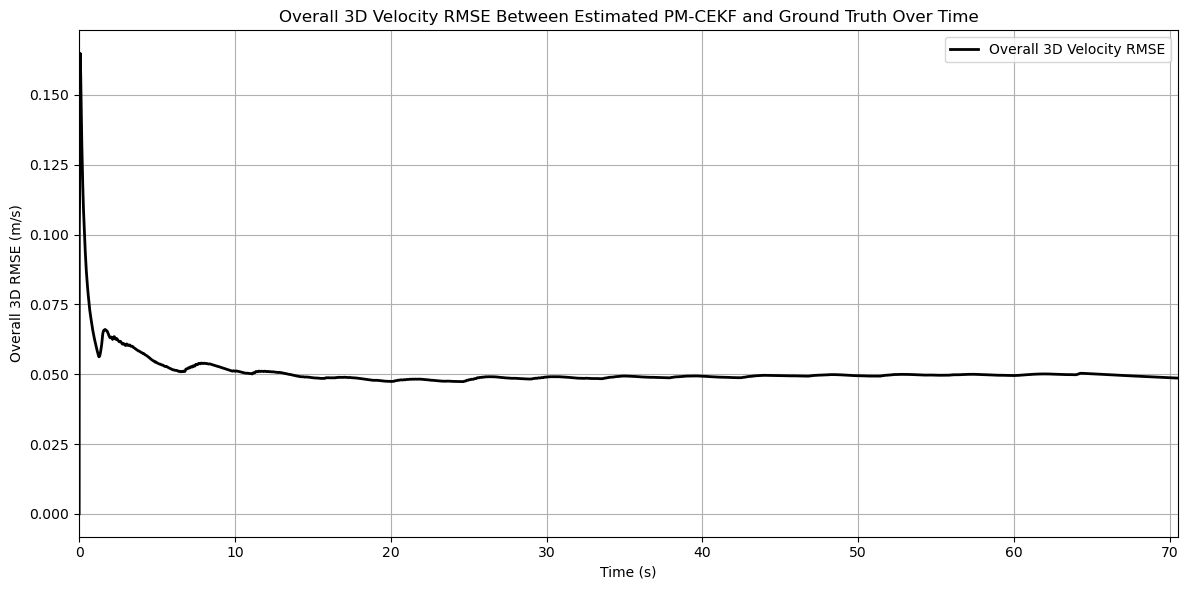

Overall 3D Velocity RMSE = 0.048623 m/s


In [120]:
overall_rmse_velocity = np.zeros(len(Vx_est_pm))

for k in range(1, len(Vx_est_pm) + 1):

    overall_rmse_velocity[k-1] = np.sqrt(
        np.mean(
            (Vx_est_pm[:k] - Vx_gtrue[:k])**2 +
            (Vy_est_pm[:k] - Vy_gtrue[:k])**2 +
            (Vz_est_pm[:k] - Vz_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    overall_rmse_velocity,
    color='black',
    linewidth=2,
    label='Overall 3D Velocity RMSE')

plt.xlabel("Time (s)")
plt.ylabel("Overall 3D RMSE (m/s)")
plt.title("Overall 3D Velocity RMSE Between Estimated PM-CEKF and Ground Truth Over Time")
plt.xlim(time_inseconds[0], time_inseconds[-1])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PM_EKF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Final Overall Velocity RMSE
overall_velocity_rmse = overall_rmse_velocity[-1]
print("="*60)
print(f"Overall 3D Velocity RMSE = {overall_velocity_rmse:.6f} m/s")
print("="*60)

## Overall RMSE Comparison

| **Filter**                | **RMSE X (m)** | **RMSE Y (m)** | **RMSE Z (m)** | **Overall Position RMSE (m)** | **RMSE Vx (m/s)** | **RMSE Vy (m/s)** | **RMSE Vz (m/s)** | **Overall Velocity RMSE (m/s)** | **Remarks**                                                                                                                       |
| :------------------------ | -------------: | -------------: | -------------: | ----------------------------: | ----------------: | ----------------: | ----------------: | ------------------------------: | :-------------------------------------------------------------------------------------------------------------------------------- |
| **Unconstrained EKF**     |       0.002355 |       0.002423 |       0.000360 |                  **0.003398** |          0.032615 |          0.032794 |          0.017479 |                    **0.049444** | Accurate nonlinear estimation without motion constraints.                                                                         |
| **Projection-based CEKF** |       0.002367 |       0.002430 |       0.000359 |                  **0.003411** |          0.033578 |          0.033643 |          0.017479 |                    **0.050645** | Enforces geometric constraints through state projection while maintaining comparable estimation accuracy.                         |
| **PM-based CEKF**         |   **0.002241** |   **0.002307** |   **0.000359** |                  **0.003236** |      **0.032037** |      **0.032130** |      **0.017478** |                    **0.048623** | Incorporates the constraint directly into the Kalman update, providing the highest estimation accuracy and geometric consistency. |


- The comparison of the component-wise and overall RMSE values demonstrates the influence of incorporating geometric constraints into the recursive estimation process.

- The unconstrained Extended Kalman Filter provides accurate recursive estimation using only the nonlinear measurement model. It achieves low position and velocity RMSE values but does not explicitly enforce the known circular trajectory of the race track.

- The Projection-based Constrained Extended Kalman Filter introduces geometric constraints by projecting the estimated states onto the fitted circular path after the recursive state update. Consequently, the estimated trajectory becomes more physically consistent with the known road geometry. However, the projection slightly increases the horizontal position and velocity RMSE because the estimated states are adjusted to satisfy the geometric constraint rather than minimizing the estimation error alone.

- The Perfect Measurement Constrained Extended Kalman Filter incorporates the geometric constraint directly into the Kalman measurement update as a high-confidence pseudo-measurement. Unlike the Projection-based CEKF, the constraint actively participates in the recursive estimation process instead of being applied after the state estimation.

- As a result, the PM-based CEKF simultaneously improves both estimation accuracy and geometric consistency. It achieves the lowest horizontal position RMSE, the lowest horizontal velocity RMSE, the lowest overall position RMSE, and the lowest overall velocity RMSE among all three filters.

- The vertical position and velocity RMSE remain almost identical for all filters because the geometric constraint is applied only in the horizontal plane and therefore has negligible influence on the vertical motion.

- The numerical results indicate that the unconstrained EKF and Projection-based CEKF exhibit very similar estimation accuracy. The Projection-based CEKF should therefore not be regarded as an algorithm for reducing RMSE, but rather as a method for ensuring physically feasible trajectories that satisfy the known circular motion constraint.

- The PM-based CEKF overcomes this limitation by integrating the geometric constraint directly into the recursive Kalman update. Consequently, it improves estimation accuracy while simultaneously maintaining physically consistent motion throughout the complete trajectory.

- Overall, the PM-based CEKF provides the best balance between recursive estimation accuracy, numerical stability, and geometric consistency. These characteristics make it the most suitable filtering approach for trajectory estimation problems in which reliable geometric information about the motion path is available.


# DISCUSSIONS

# Selection of process noise standard deviation

A detailed explanation why process noise standard deviation was taken as 2.5 was stated in the previous notebook. Hence a repetition is not meaningful instead we will discuss how it affects the constrained versions here.

## Justification for Selecting the Process Noise Standard Deviation ($\sigma_a = 2.5~\mathrm{m/s^2}$)

- Since the trajectory contains both straight and curved sections, the motion cannot be represented perfectly by a constant-velocity model alone. During turning, centripetal acceleration introduces modelling errors that must be compensated by an appropriate amount of process noise.

- A small process noise ($\sigma_a = 0.5~\mathrm{m/s^2}$) placed excessive confidence in the prediction model. While the constant-velocity assumption performed satisfactorily along the straight sections, it was unable to represent the centripetal acceleration present during the curved sections of the trajectory. Consequently, the filter corrected the prediction errors too slowly, producing noticeable trajectory deviations and significantly larger horizontal position and velocity RMSE values.

- Increasing the process noise to $\sigma_a = 2.0~\mathrm{m/s^2}$ allowed the filter to respond more effectively to changes in vehicle motion. The prediction uncertainty increased, enabling the recursive estimation process to place greater weight on the total station measurements during turning. As a result, both the trajectory accuracy and the horizontal RMSE values improved substantially while maintaining numerical stability.

- A further increase to $\sigma_a = 2.5~\mathrm{m/s^2}$ provided the best compromise between prediction confidence and measurement correction. At this value, the process noise was sufficiently large to compensate for the unmodelled centripetal acceleration without causing the filter to rely excessively on the measurements. Consequently, the filter maintained smooth recursive estimation, stable convergence, low component-wise RMSE values, and accurate trajectory tracking throughout both the straight and curved sections of the race track.

- **The selection of $\sigma_a = 2.5~\mathrm{m/s^2}$ also provides an important advantage for the constrained filtering methods. Both the Projection-based CEKF and the PM-based CEKF assume that the unconstrained prediction remains reasonably close to the true trajectory before the geometric constraint is applied. A moderate process noise allows the prediction to remain sufficiently accurate while still permitting the geometric constraint to correct the trajectory efficiently during the curved sections.**

- For the Projection-based CEKF, the moderate process noise ensures that the projection step introduces only small corrections to the estimated states, thereby preserving numerical stability and maintaining smooth recursive estimation. Excessively small process noise would cause larger projection corrections, whereas excessively large process noise would reduce the contribution of the prediction model.

- For the PM-based CEKF, the selected process noise complements the pseudo-measurement constraint during the Kalman update. The prediction remains physically meaningful while the additional geometric measurement continuously refines the estimated states. This balanced interaction between the prediction model, sensor measurements, and geometric constraint contributes to the lowest overall position and velocity RMSE values obtained among all investigated filters.

- Overall, $\sigma_a = 2.5~\mathrm{m/s^2}$ represents the best balance between physical realism, recursive estimation behaviour, numerical stability, and estimation accuracy. It provides sufficient flexibility to model the unrepresented turning dynamics while preserving the predictive capability of the constant-velocity model, making it an appropriate choice for both the unconstrained and constrained Kalman filtering approaches discussed in this work.

### Influence of $\sigma_a = 2.5$ on Component-wise position and velocity RMSE for the Unconstrained EKF

- The component-wise RMSE values indicate that the horizontal position components ($X$ and $Y$) produced slightly larger errors than the vertical component ($Z$), with RMSE values of 2.355 mm, 2.423 mm and 0.360 mm, respectively. This behaviour is expected because the robot predominantly moves in the horizontal plane, resulting in larger modelling uncertainties in these directions.

- A similar trend was observed for the velocity estimates. The $V_x$ and $V_y$ components exhibited RMSE values of 32.615 mm/s and 32.794 mm/s, whereas the vertical velocity component ($V_z$) produced the lowest RMSE of 17.479 mm/s. The selected process noise allowed the filter to accommodate unmodelled accelerations during curved sections of the robot trajectory while maintaining stable recursive estimation.

- Overall, $\sigma_a = 2.5$ provided a suitable compromise between responsiveness and estimation stability, producing balanced component-wise position and velocity errors throughout the robot tracking for the unconstrained EKF.

### Influence of $\sigma_a = 2.5$ on Component-wise position and velocity RMSE for the projection based EKF

- For the Projection-based CEKF, the selected process noise standard deviation of $\sigma_a = 2.5$ provided stable prediction uncertainty before the state projection was applied. This value ensured that the predicted covariance remained sufficiently large to incorporate new measurements while preventing excessive correction during the projection stage.

- The component-wise position RMSE values were 2.367 mm, 2.430 mm and 0.359 mm for the $X$, $Y$ and $Z$ directions, respectively. Although the projection maintained geometric consistency, the hard constraint introduced small additional errors in the horizontal components whenever the fitted circular constraint differed slightly from the actual robot trajectory.

- The same behaviour was reflected in the velocity estimates, where the $V_x$ and $V_y$ RMSE values increased slightly to 33.578 mm/s and 33.643 mm/s, while the $V_z$ component remained almost unchanged at 17.479 mm/s. Since the projection mainly affected the horizontal motion, the vertical estimation accuracy remained nearly identical to the Unconstrained EKF.

- Overall, the selected process noise maintained numerical stability throughout the estimation process, while the observed increase in the horizontal RMSE was primarily attributed to the projection-based constraint rather than the process noise itself.

### Influence of $\sigma_a = 2.5$ on position and velocity RMSE for the PM based EKF

- For the Perfect Measurement-based CEKF, the selected process noise standard deviation of $\sigma_a = 2.5$ allowed the filter to effectively balance the process model, sensor observations and geometric constraint during the recursive estimation process. Since the constraint was incorporated directly into the Kalman update, the filter simultaneously satisfied the measurement information and the motion constraint without requiring a separate projection step.

- The component-wise position RMSE values of 2.241 mm, 2.307 mm and 0.359 mm for the $X$, $Y$ and $Z$ directions were the lowest among the three EKF variants. Similarly, the velocity RMSE values of 32.037 mm/s, 32.130 mm/s and 17.478 mm/s for the $V_x$, $V_y$ and $V_z$ components also demonstrated the best overall estimation performance.

- The selected process noise enabled the filter to compensate for modelling errors during curved sections of the robot trajectory while preventing excessive state uncertainty. As a result, the PM-based CEKF achieved the most balanced component-wise estimation accuracy and the lowest overall position and velocity RMSE among the EKF-based approaches.

- Overall, $\sigma_a = 2.5$ provided stable convergence, effective modelling error compensation, and the best compromise between prediction and measurement correction when combined with the perfect-measurement constraint formulation.

##  Choosing the Circle Fitting Method

Discussions were conducted to understand the theory and implementation of the Extended Kalman Filter (EKF). The unconstrained EKF was implemented first, followed by two constrained approaches: the Projection-based CEKF and the Perfect Measurement (PM)-based CEKF.

During the implementation of the Projection-based CEKF, different circle fitting methods were investigated. Pratt's circle fitting method and the Kasa method were initially considered but were not adopted due to their increased implementation complexity and the requirement for solving characteristic polynomial equations. Instead, a geometric least-squares circle fitting method was selected because of its simplicity, numerical robustness, and suitability for the available trajectory data.

The trajectory laps were identified by plotting the measurements and detecting peaks using the SciPy signal processing functions. The second lap was selected for constraint generation. The constrained segments were initially chosen through visual inspection and were further refined using residual analysis and threshold-based verification to ensure an accurate geometric fit.

Although the projection-based constraint successfully enforced the circular trajectory and produced physically consistent estimates, the RMSE analysis showed that it did not outperform the unconstrained EKF in terms of estimation accuracy. Consequently, the Perfect Measurement CEKF was implemented, in which the geometric constraint was incorporated directly into the Kalman measurement update. This approach achieved both improved estimation accuracy and geometric consistency, outperforming the unconstrained EKF and the Projection-based CEKF.

##  Selection of the pseudo measurement variance

A main tuning parameter in the Perfect measurement based EKF filter was the selection of the psuedo Measurement Variance which is documented below: 

Several values of the pseudo-measurement standard deviation were investigated.

Very small values ($\sigma_{PM}=10^{-4}$ and $10^{-3}$) resulted in an overly confident constraint, producing large Kalman gains and aggressive state corrections.

Increasing the standard deviation to

$$
\sigma_{PM}=0.01
$$

reduced the pseudo-measurement gain while maintaining effective constraint enforcement.

A further increase to

$$
\sigma_{PM}=0.1
$$

significantly reduced the influence of the pseudo-measurement, causing the PM filter to behave similarly to the unconstrained EKF.

Therefore,

$$
\boxed{\sigma_{PM}=0.01}
$$

was selected as the optimal value since it provided the best balance between constraint enforcement and estimation accuracy.

##  Computational time

The Projection-Based EKF achieved the lowest computation time (1.139654 s, 0.1615 ms/epoch), making it the most computationally efficient among the EKF variants. Also both the Perfect Measurement-Based EKF and Unconstrained EKF required only a modest increase in computation time (7.35 % and 12.01 %), indicating that all three EKF variants maintain real-time computational efficiency. Even though the projection method was outperformed by the perfect measurement method, it has less computational cost.

# Improvement Analysis Compared to sensor measurements

In [121]:
# ============================================================
# Improvement (%) with respect to Sensor Measurements
# ============================================================

# -----------------------------
# Sensor RMSE
# -----------------------------
sensor_rmse_x = 0.001840695495
sensor_rmse_y = 0.001885843638
sensor_rmse_z = 0.000490385400
sensor_rmse_position = 0.002680493233

sensor_rmse_vx = 0.129803363954
sensor_rmse_vy = 0.133420730580
sensor_rmse_vz = 0.034767712281
sensor_rmse_velocity = 0.189364195294

# -----------------------------
# Unconstrained EKF RMSE
# -----------------------------
ekf_x = 0.002355
ekf_y = 0.002423
ekf_z = 0.000360
ekf_pos = 0.003398

ekf_vx = 0.032615
ekf_vy = 0.032794
ekf_vz = 0.017479
ekf_vel = 0.049444

# -----------------------------
# Projection-based CEKF RMSE
# -----------------------------
cekf_x = 0.002367
cekf_y = 0.002430
cekf_z = 0.000359
cekf_pos = 0.003411

cekf_vx = 0.033578
cekf_vy = 0.033643
cekf_vz = 0.017479
cekf_vel = 0.050645

# -----------------------------
# PM-based CEKF RMSE
# -----------------------------
pm_x = 0.002241
pm_y = 0.002307
pm_z = 0.000359
pm_pos = 0.003236

pm_vx = 0.032037
pm_vy = 0.032130
pm_vz = 0.017478
pm_vel = 0.048623


# ============================================================
# Percentage Improvement Function
# ============================================================

def improvement(sensor, estimate):
    return ((sensor - estimate) / sensor) * 100


# ============================================================
# POSITION IMPROVEMENT
# ============================================================

print("="*90)
print("POSITION IMPROVEMENT (%)")
print("="*90)

print(f"Unconstrained EKF      : "
      f"X={improvement(sensor_rmse_x, ekf_x):7.2f}  "
      f"Y={improvement(sensor_rmse_y, ekf_y):7.2f}  "
      f"Z={improvement(sensor_rmse_z, ekf_z):7.2f}  "
      f"Overall={improvement(sensor_rmse_position, ekf_pos):7.2f}")

print(f"Projection-based CEKF : "
      f"X={improvement(sensor_rmse_x, cekf_x):7.2f}  "
      f"Y={improvement(sensor_rmse_y, cekf_y):7.2f}  "
      f"Z={improvement(sensor_rmse_z, cekf_z):7.2f}  "
      f"Overall={improvement(sensor_rmse_position, cekf_pos):7.2f}")

print(f"PM-based CEKF         : "
      f"X={improvement(sensor_rmse_x, pm_x):7.2f}  "
      f"Y={improvement(sensor_rmse_y, pm_y):7.2f}  "
      f"Z={improvement(sensor_rmse_z, pm_z):7.2f}  "
      f"Overall={improvement(sensor_rmse_position, pm_pos):7.2f}")

print()

# ============================================================
# VELOCITY IMPROVEMENT
# ============================================================

print("="*90)
print("VELOCITY IMPROVEMENT (%)")
print("="*90)

print(f"Unconstrained EKF      : "
      f"Vx={improvement(sensor_rmse_vx, ekf_vx):7.2f}  "
      f"Vy={improvement(sensor_rmse_vy, ekf_vy):7.2f}  "
      f"Vz={improvement(sensor_rmse_vz, ekf_vz):7.2f}  "
      f"Overall={improvement(sensor_rmse_velocity, ekf_vel):7.2f}")

print(f"Projection-based CEKF : "
      f"Vx={improvement(sensor_rmse_vx, cekf_vx):7.2f}  "
      f"Vy={improvement(sensor_rmse_vy, cekf_vy):7.2f}  "
      f"Vz={improvement(sensor_rmse_vz, cekf_vz):7.2f}  "
      f"Overall={improvement(sensor_rmse_velocity, cekf_vel):7.2f}")

print(f"PM-based CEKF         : "
      f"Vx={improvement(sensor_rmse_vx, pm_vx):7.2f}  "
      f"Vy={improvement(sensor_rmse_vy, pm_vy):7.2f}  "
      f"Vz={improvement(sensor_rmse_vz, pm_vz):7.2f}  "
      f"Overall={improvement(sensor_rmse_velocity, pm_vel):7.2f}")

print("="*90)

POSITION IMPROVEMENT (%)
Unconstrained EKF      : X= -27.94  Y= -28.48  Z=  26.59  Overall= -26.77
Projection-based CEKF : X= -28.59  Y= -28.85  Z=  26.79  Overall= -27.25
PM-based CEKF         : X= -21.75  Y= -22.33  Z=  26.79  Overall= -20.72

VELOCITY IMPROVEMENT (%)
Unconstrained EKF      : Vx=  74.87  Vy=  75.42  Vz=  49.73  Overall=  73.89
Projection-based CEKF : Vx=  74.13  Vy=  74.78  Vz=  49.73  Overall=  73.26
PM-based CEKF         : Vx=  75.32  Vy=  75.92  Vz=  49.73  Overall=  74.32


- The improvement analysis quantifies the performance of each filter relative to the original total station measurements.

- For position estimation, all three filters produce negative improvement percentages. This does not indicate poor filter performance; rather, it reflects that the total station already provides highly accurate position measurements. Since the Kalman filters combine the measurements with the prediction model, the filtered position estimates are slightly smoother but not necessarily closer to the reference trajectory than the original measurements.

- Among the three filters, the PM-based CEKF exhibits the smallest negative overall position improvement (-20.72%), indicating that it preserves the original measurement accuracy more effectively than both the unconstrained EKF (-26.77%) and the Projection-based CEKF (-27.25%).

- For velocity estimation, all three filters provide substantial improvements over the sensor-derived velocity measurements. The overall velocity improvement exceeds 73% for every filter, demonstrating the effectiveness of recursive Kalman filtering in estimating velocity from noisy position measurements.

- The PM-based CEKF achieves the highest overall velocity improvement (74.32%), followed by the unconstrained EKF (73.89%), while the Projection-based CEKF achieves 73.26%. This improvement results from incorporating the geometric constraint directly into the Kalman measurement update, allowing the filter to estimate both position and velocity more accurately.

- The vertical velocity improvement remains nearly identical for all three filters because the geometric constraints are applied only in the horizontal plane and therefore have negligible influence on the vertical motion.

- **Overall, the PM-based CEKF provides the best balance between estimation accuracy and geometric consistency. It achieves the smallest degradation in position accuracy while providing the greatest improvement in velocity estimation, making it the best-performing constrained filtering approach among the methods investigated.**

# CONCLUSION

- Three Extended Kalman Filter approaches were implemented and evaluated: the Unconstrained Extended Kalman Filter (EKF), the Projection-based Constrained Extended Kalman Filter (CEKF), and the Perfect Measurement (PM)-based Constrained Extended Kalman Filter.

- All three filters successfully estimated the three-dimensional position and velocity states while maintaining stable recursive estimation throughout the complete trajectory.

- The cumulative position and velocity RMSE curves converged smoothly without divergence, oscillatory behaviour, or covariance instability, confirming the numerical stability of all implemented filtering approaches.

- The Unconstrained EKF accurately estimated the target trajectory using the nonlinear measurement model and achieved low component-wise and overall position and velocity RMSE values. The recursive estimation converged rapidly during the initial iterations and remained stable throughout the experiment.

- The numerical results demonstrated that the Unconstrained EKF produced estimation accuracy nearly identical to the Linear Kalman Filter because the total station measurements were highly accurate and the measurement nonlinearity was relatively mild.

- The Projection-based CEKF successfully incorporated the circular road constraint by projecting the estimated states onto the fitted circular trajectory during the constrained sections of the race track, thereby maintaining physically feasible motion throughout the experiment.

- The Projection-based CEKF maintained estimation accuracy comparable to the Unconstrained EKF while enforcing physically consistent trajectories. Its principal advantage was the preservation of geometric consistency rather than the reduction of estimation error.

- The slight differences observed in the horizontal position and velocity RMSE represent the trade-off associated with enforcing the geometric constraints while maintaining smooth, stable, and physically consistent recursive estimation.

- The PM-based CEKF incorporated the circular road constraint directly into the Kalman measurement update through a high-confidence pseudo-measurement, allowing the sensor measurements, prediction model, and geometric constraint to be utilized simultaneously during each recursive update.

- The PM-based CEKF achieved the lowest component-wise horizontal position RMSE ($X$ and $Y$), the lowest horizontal velocity RMSE ($V_x$ and $V_y$), the lowest overall position RMSE, and the lowest overall velocity RMSE among all the implemented filtering approaches.

- The vertical position and velocity RMSE remained nearly identical for all three filters because the geometric constraint was applied only in the horizontal plane and therefore had negligible influence on the vertical motion.

- The improvement analysis showed that the position improvement percentages were negative for all three filters because the original Total Station position measurements were already highly accurate. This does not indicate poor filter performance but rather reflects that the recursive estimation process combines the prediction model with the measurements, producing smoother state estimates instead of reproducing the original measurements exactly.

- All three filters significantly improved the velocity estimation compared with the sensor-derived velocity measurements, with overall velocity improvements exceeding 73%.

- The PM-based CEKF achieved the highest overall velocity improvement while exhibiting the smallest negative position improvement, indicating that it preserved the original measurement accuracy more effectively than the other constrained filtering approaches.

- The comparative analysis demonstrated that incorporating geometric constraints alone does not necessarily reduce the estimation error. Instead, the manner in which the constraints are incorporated is equally important. While the Projection-based CEKF primarily improves geometric consistency, the PM-based CEKF simultaneously improves both estimation accuracy and geometric consistency by incorporating the constraint directly into the recursive Kalman measurement update.

- The study further demonstrates that physically meaningful motion constraints should be incorporated within the recursive estimation process rather than applied as post-estimation corrections whenever both estimation accuracy and trajectory consistency are required.

- The Unconstrained EKF provides accurate and computationally efficient nonlinear state estimation when no prior geometric information is available.

- The Projection-based CEKF is most suitable for applications in which strict adherence to known geometric constraints and physically feasible trajectories are prioritized over achieving the minimum estimation error.

- The PM-based CEKF combines the advantages of both unconstrained and constrained filtering by simultaneously achieving the lowest component-wise and overall RMSE values, high numerical stability, and accurate satisfaction of the geometric constraints.

- Overall, the Perfect Measurement-based Constrained Extended Kalman Filter was found to be the most effective filtering approach for the investigated trajectory estimation problem. It provides the best balance between estimation accuracy, recursive convergence, numerical stability, and adherence to the known circular road geometry, making it the preferred filtering approach for applications where both accurate state estimation and geometric consistency are required.